# 03 · Quality control for CD14+ monocytes

Attach the Stage 02 H5AD and manifest. Review QC by donor and condition, then retain source-annotated CD14+ demuxlet singlets with more than 100 detected genes and a hemoglobin UMI fraction below 90%. The cohort H5AD and audit feed Stage 04.


## 1. Input checkpoint verification

Check the Stage 02 H5AD against its saved SHA-256 and dimensions.


In [1]:
%pip install "anndata==0.13.4"

In [2]:
from pathlib import Path
import hashlib
import json

INPUT_DIR = Path("/kaggle/input")

# Locate the saved H5AD from Notebook 02
h5ad_files = sorted(
    INPUT_DIR.rglob("ifnb_batch2_raw_counts.h5ad")
)

assert len(h5ad_files) == 1, (
    f"Expected one H5AD checkpoint, found {len(h5ad_files)}"
)

H5AD_PATH = h5ad_files[0]

SOURCE_PROJECT = H5AD_PATH.parents[2]

MANIFEST_PATH = (
    SOURCE_PROJECT
    / "results"
    / "audit"
    / "stage02_anndata_roundtrip.json"
)

assert MANIFEST_PATH.is_file()

# Read Stage 02 verification manifest
manifest = json.loads(
    MANIFEST_PATH.read_text(encoding="utf-8")
)

# Verify checksum of the actual saved H5AD
with H5AD_PATH.open("rb") as stream:
    actual_sha256 = hashlib.file_digest(
        stream, "sha256"
    ).hexdigest()

assert actual_sha256 == manifest["sha256"]
assert manifest["roundtrip"] == "PASS"

# Verify expected dataset characteristics
assert manifest["n_obs"] == 29065
assert manifest["n_vars"] == 35635
assert manifest["counts_nnz"] == 17570845
assert manifest["total_umi"] == 48600925

# Initialize Stage 03 output directories
PROJECT = Path("/kaggle/working/kang_ifnb")
PROCESSED_DIR = PROJECT / "data" / "processed"
AUDIT_DIR = PROJECT / "results" / "audit"
FIGURES_DIR = PROJECT / "results" / "figures"

for folder in [PROCESSED_DIR, AUDIT_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("H5AD:", H5AD_PATH)
print("Size (MB):", round(H5AD_PATH.stat().st_size / 1e6, 2))
print("SHA-256:", actual_sha256)
print("Observations:", manifest["n_obs"])
print("Genes:", manifest["n_vars"])
print("Total UMI:", manifest["total_umi"])

print("\nSTAGE 03 INPUT CHECKPOINT: PASS")

H5AD: /kaggle/input/notebooks/tthanhh811/02-ifnb-anndata/kang_ifnb/data/processed/ifnb_batch2_raw_counts.h5ad
Size (MB): 155.04
SHA-256: 7fe3231e8c53354c233a3b16943fa6196e6b37ef74a3c1471c1087c9ccfc6153
Observations: 29065
Genes: 35635
Total UMI: 48600925

STAGE 03 INPUT CHECKPOINT: PASS


## 2. Load AnnData and verify the pre-QC state

Verify counts and metadata before applying QC.


In [3]:
import sys
import json
from importlib.metadata import version

import anndata as ad
import numpy as np
import pandas as pd
import scipy
from scipy import sparse

# --------------------------------------------------
# 1. Check actual package versions
# --------------------------------------------------

packages = {
    name: version(name)
    for name in [
        "anndata", "numpy", "pandas", "scipy", "h5py"
    ]
}

print("Python:", sys.version.split()[0])
print("Packages:")
print(json.dumps(packages, indent=2))

assert packages["anndata"] == "0.13.4"

# Compare with the validated Stage 02 environment
stage02_packages = {
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scipy": "1.16.3",
    "h5py": "3.14.0",
}

changes = {
    name: {
        "stage02": expected,
        "stage03": packages[name],
    }
    for name, expected in stage02_packages.items()
    if packages[name] != expected
}

print("\nDependency changes:", changes)

assert not changes, (
    "Runtime differs from Stage 02; review before continuing."
)

# --------------------------------------------------
# 2. Load H5AD into memory
# --------------------------------------------------

adata = ad.read_h5ad(H5AD_PATH)

print("\nLoaded AnnData:")
print(adata)

# --------------------------------------------------
# 3. Verify dimensions and sparse counts
# --------------------------------------------------

assert adata.shape == (29065, 35635)

assert sparse.issparse(adata.X)
assert adata.X.format == "csr"
assert adata.X.dtype == np.int64

assert "counts" in adata.layers

raw_counts = adata.layers["counts"]

assert sparse.issparse(raw_counts)
assert raw_counts.format == "csr"
assert raw_counts.dtype == np.int64

assert raw_counts.nnz == 17570845
assert int(raw_counts.sum()) == 48600925

# X must still be identical to the raw-count layer
assert (adata.X != raw_counts).nnz == 0

# No nonfinite or negative stored counts
assert np.isfinite(raw_counts.data).all()
assert (raw_counts.data >= 0).all()

assert adata.raw is None
assert not adata.isbacked

print("\nRaw count integrity: PASS")

# --------------------------------------------------
# 4. Verify observation and gene metadata
# --------------------------------------------------

required_obs = [
    "source_sample_id",
    "condition",
    "donor_id",
    "barcode_original",
    "metadata_cell_id",
    "cell_type_reference",
    "demuxlet_class",
]

assert all(
    col in adata.obs.columns
    for col in required_obs
)

assert adata.obs_names.is_unique
assert adata.var_names.is_unique
assert "gene_symbol" in adata.var.columns

assert adata.obs["cell_type_reference"].isna().sum() == 9

print("Metadata integrity: PASS")

# --------------------------------------------------
# 5. Verify source singlet pairing
# --------------------------------------------------

singlets = adata.obs.loc[
    adata.obs["demuxlet_class"].eq("singlet")
]

pairs = pd.crosstab(
    singlets["donor_id"].astype(str),
    singlets["condition"].astype(str),
).reindex(
    columns=["ctrl", "stim"],
    fill_value=0,
).sort_index()

assert len(singlets) == 24679
assert pairs.shape == (8, 2)
assert (pairs > 0).all().all()

print("\nSource singlets by donor and condition:")
display(pairs)

print("\nSTAGE 03 ANNDATA LOADING: PASS")

Python: 3.13.18
Packages:
{
  "anndata": "0.13.4",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scipy": "1.16.3",
  "h5py": "3.14.0"
}

Dependency changes: {}

Loaded AnnData:
AnnData object with n_obs × n_vars = 29065 × 35635
    obs: 'source_sample_id', 'condition', 'matrix_column_zero_based', 'barcode_original', 'metadata_cell_id', 'source_tsne1', 'source_tsne2', 'donor_id', 'cluster_reference', 'cell_type_reference', 'demuxlet_class'
    var: 'gene_symbol'
    uns: 'provenance'
    layers: 'counts', None (.X)

Raw count integrity: PASS
Metadata integrity: PASS

Source singlets by donor and condition:


condition,ctrl,stim
donor_id,,
101,858,1166
1015,2738,2352
1016,1723,1635
1039,461,647
107,517,525
1244,1879,1464
1256,2108,2026
1488,2031,2549



STAGE 03 ANNDATA LOADING: PASS


## 3. Compute pre-QC library-size metrics

Compute total UMIs and detected genes per barcode.


In [4]:
import numpy as np
from scipy import sparse

# --------------------------------------------------
# 1. Use the original count layer
# --------------------------------------------------

counts = adata.layers["counts"]

assert sparse.isspmatrix_csr(counts)
assert counts.dtype == np.int64
assert counts.shape == (29065, 35635)

# The validated Stage 01 matrices have no stored zeros.
# This matters when counting nonzero entries per row.
assert np.all(counts.data > 0)
assert counts.has_canonical_format

# --------------------------------------------------
# 2. Total UMI counts per barcode
# --------------------------------------------------

total_counts = np.asarray(
    counts.sum(axis=1)
).ravel().astype(np.int64)

# --------------------------------------------------
# 3. Number of detected genes per barcode
# --------------------------------------------------

# In CSR format, indptr marks the start/end
# of each row's stored nonzero entries.
n_genes_by_counts = np.diff(
    counts.indptr
).astype(np.int64)

# --------------------------------------------------
# 4. Validate calculated metrics
# --------------------------------------------------

assert len(total_counts) == adata.n_obs
assert len(n_genes_by_counts) == adata.n_obs

assert np.all(total_counts >= 0)
assert np.all(n_genes_by_counts >= 0)

assert np.all(n_genes_by_counts <= adata.n_vars)

# Every detected gene has at least one UMI
assert np.all(total_counts >= n_genes_by_counts)

assert int(total_counts.sum()) == 48600925

assert (
    int(n_genes_by_counts.sum())
    == 17570845
)

# A barcode with zero UMI must have zero detected genes
assert np.array_equal(
    total_counts == 0,
    n_genes_by_counts == 0,
)

# --------------------------------------------------
# 5. Attach metrics to observation metadata
# --------------------------------------------------

adata.obs["total_counts"] = total_counts
adata.obs["n_genes_by_counts"] = n_genes_by_counts

# --------------------------------------------------
# 6. Report results
# --------------------------------------------------

n_zero_umi = int((total_counts == 0).sum())

print("Barcodes:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Total UMI:", int(total_counts.sum()))
print("Sum of detected gene entries:",
      int(n_genes_by_counts.sum()))
print("Zero-UMI barcodes:", n_zero_umi)

print("\nFirst five barcode metrics:")
display(
    adata.obs[
        ["total_counts", "n_genes_by_counts"]
    ].head()
)

print("\nPRE-QC LIBRARY METRICS: PASS")

Barcodes: 29065
Genes: 35635
Total UMI: 48600925
Sum of detected gene entries: 17570845
Zero-UMI barcodes: 0

First five barcode metrics:


,total_counts,n_genes_by_counts
cell_id,,
GSM2560248__AAACATACAATGCC-1,2191,852
GSM2560248__AAACATACATTTCC-1,3018,878
GSM2560248__AAACATACCAGAAA-1,2481,713
GSM2560248__AAACATACCAGCTA-1,3157,950
GSM2560248__AAACATACCATGCA-1,703,337



PRE-QC LIBRARY METRICS: PASS


In [5]:
# --------------------------------------------------
# 1. Summary statistics across all barcodes
# --------------------------------------------------

qc_descriptive = adata.obs[
    ["total_counts", "n_genes_by_counts"]
].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

print("Overall pre-QC distributions:")
display(qc_descriptive.round(2))

# --------------------------------------------------
# 2. Per-source summary
# --------------------------------------------------

qc_by_source = (
    adata.obs
    .groupby("source_sample_id", observed=True)
    .agg(
        n_barcodes=("total_counts", "size"),
        total_umi=("total_counts", "sum"),
        detected_entries=("n_genes_by_counts", "sum"),
        zero_umi_barcodes=(
            "total_counts",
            lambda s: int((s == 0).sum()),
        ),
        median_umi=("total_counts", "median"),
        median_genes=("n_genes_by_counts", "median"),
    )
)

# --------------------------------------------------
# 3. Validate against original count audit
# --------------------------------------------------

expected = {
    "GSM2560248": {
        "n_barcodes": 14619,
        "total_umi": 23540929,
        "detected_entries": 8732747,
    },
    "GSM2560249": {
        "n_barcodes": 14446,
        "total_umi": 25059996,
        "detected_entries": 8838098,
    },
}

assert set(qc_by_source.index) == set(expected)

for accession, values in expected.items():
    for metric, reference in values.items():
        assert (
            int(qc_by_source.loc[accession, metric])
            == reference
        ), f"{accession}: mismatch in {metric}"

# --------------------------------------------------
# 4. Save summary
# --------------------------------------------------

summary_path = (
    AUDIT_DIR / "stage03_pre_qc_metrics_by_source.tsv"
)

qc_by_source.to_csv(
    summary_path,
    sep="\t",
)

print("\nQC metrics by source sample:")
display(qc_by_source)

print("\nAudit saved:", summary_path)
print("Cells removed: 0")
print("Genes removed: 0")

print("\nSTAGE 03 LIBRARY METRICS VALIDATION: PASS")

Overall pre-QC distributions:


,total_counts,n_genes_by_counts
count,29065.00,29065.00
mean,1672.15,604.54
std,1007.68,237.43
min,562.00,12.00
5%,710.00,348.00
25%,987.00,445.00
50%,1301.00,533.00
75%,2079.00,718.00
95%,3750.80,1078.00
99%,5121.72,1362.00



QC metrics by source sample:


,n_barcodes,total_umi,detected_entries,zero_umi_barcodes,median_umi,median_genes
source_sample_id,,,,,,
GSM2560248,14619,23540929,8732747,0,1256.0,520.0
GSM2560249,14446,25059996,8838098,0,1346.0,546.0



Audit saved: /kaggle/working/kang_ifnb/results/audit/stage03_pre_qc_metrics_by_source.tsv
Cells removed: 0
Genes removed: 0

STAGE 03 LIBRARY METRICS VALIDATION: PASS


## 4. Donor-aware pre-QC assessment

Compare library size and detected genes across donor–condition groups.


In [6]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Prepare metadata for descriptive analysis
# --------------------------------------------------

qc = adata.obs[
    [
        "donor_id",
        "condition",
        "demuxlet_class",
        "total_counts",
        "n_genes_by_counts",
    ]
].copy()

assert qc[[
    "donor_id",
    "condition",
    "demuxlet_class",
]].notna().all().all()

for col in ["donor_id", "condition", "demuxlet_class"]:
    qc[col] = qc[col].astype(str)

assert len(qc) == 29065

# --------------------------------------------------
# 2. Define descriptive statistics
# --------------------------------------------------

def summarize_qc(frame):
    return (
        frame.groupby(
            ["donor_id", "condition"],
            observed=True,
        )
        .agg(
            n_barcodes=("total_counts", "size"),
            total_umi=("total_counts", "sum"),

            umi_mean=("total_counts", "mean"),
            umi_sd=("total_counts", "std"),
            umi_p05=("total_counts",
                     lambda x: x.quantile(0.05)),
            umi_q25=("total_counts",
                     lambda x: x.quantile(0.25)),
            umi_median=("total_counts", "median"),
            umi_q75=("total_counts",
                     lambda x: x.quantile(0.75)),
            umi_p95=("total_counts",
                     lambda x: x.quantile(0.95)),

            genes_mean=("n_genes_by_counts", "mean"),
            genes_sd=("n_genes_by_counts", "std"),
            genes_p05=("n_genes_by_counts",
                       lambda x: x.quantile(0.05)),
            genes_q25=("n_genes_by_counts",
                       lambda x: x.quantile(0.25)),
            genes_median=("n_genes_by_counts", "median"),
            genes_q75=("n_genes_by_counts",
                       lambda x: x.quantile(0.75)),
            genes_p95=("n_genes_by_counts",
                       lambda x: x.quantile(0.95)),
        )
        .reset_index()
    )

# --------------------------------------------------
# 3. All source barcodes
# --------------------------------------------------

qc_all = summarize_qc(qc)

assert len(qc_all) == 16
assert qc_all["n_barcodes"].sum() == 29065
assert qc_all["total_umi"].sum() == 48600925

# --------------------------------------------------
# 4. Source singlets only
# --------------------------------------------------

qc_singlets = summarize_qc(
    qc.loc[qc["demuxlet_class"].eq("singlet")]
)

assert len(qc_singlets) == 16
assert qc_singlets["n_barcodes"].sum() == 24679

# Every donor retains both conditions
assert (
    qc_singlets.groupby("donor_id")["condition"].nunique()
    == 2
).all()

# --------------------------------------------------
# 5. Save complete descriptive statistics
# --------------------------------------------------

qc_all.to_csv(
    AUDIT_DIR / "stage03_qc_by_donor_condition_all.tsv",
    sep="\t",
    index=False,
)

qc_singlets.to_csv(
    AUDIT_DIR / "stage03_qc_by_donor_condition_singlets.tsv",
    sep="\t",
    index=False,
)

# --------------------------------------------------
# 6. Display compact tables
# --------------------------------------------------

selected_columns = [
    "donor_id",
    "condition",
    "n_barcodes",
    "umi_q25",
    "umi_median",
    "umi_q75",
    "genes_q25",
    "genes_median",
    "genes_q75",
]

print("All source barcodes:")
display(qc_all[selected_columns])

print("\nSource singlets:")
display(qc_singlets[selected_columns])

print("\nQC GROUP SUMMARIES: PASS")

All source barcodes:


,donor_id,condition,n_barcodes,umi_q25,umi_median,umi_q75,genes_q25,genes_median,genes_q75
0,101,ctrl,1027,981.50,1338.0,2366.50,444.00,554.0,817.00
1,101,stim,1363,1032.50,1398.0,2706.00,458.00,562.0,827.00
2,1015,ctrl,3138,995.00,1315.0,2189.75,456.00,547.0,758.00
3,1015,stim,2703,1088.50,1431.0,2490.00,477.00,569.0,768.00
4,1016,ctrl,2180,840.75,1065.5,1768.00,415.00,480.0,678.25
5,1016,stim,1998,907.00,1129.0,1936.50,433.00,505.0,700.00
6,1039,ctrl,552,1072.25,1503.0,2520.25,421.00,545.0,739.25
7,1039,stim,797,1088.00,1576.0,2659.00,440.00,561.0,758.00
8,107,ctrl,645,1067.00,1548.0,2402.00,454.00,562.0,784.00
9,107,stim,641,1089.00,1519.0,2689.00,475.00,581.0,789.00



Source singlets:


,donor_id,condition,n_barcodes,umi_q25,umi_median,umi_q75,genes_q25,genes_median,genes_q75
0,101,ctrl,858,962.50,1239.5,2210.00,441.0,534.0,761.75
1,101,stim,1166,1014.00,1312.0,2376.75,452.0,546.0,756.00
2,1015,ctrl,2738,979.00,1244.0,1990.50,451.0,528.0,690.00
3,1015,stim,2352,1071.75,1349.5,2300.00,469.0,551.0,705.00
4,1016,ctrl,1723,839.00,1015.0,1489.50,414.0,469.0,594.00
5,1016,stim,1635,891.50,1084.0,1601.00,429.0,491.0,610.00
6,1039,ctrl,461,1064.00,1419.0,2321.00,435.0,543.0,674.00
7,1039,stim,647,1063.50,1486.0,2533.00,444.5,549.0,701.50
8,107,ctrl,517,1057.00,1465.0,2245.00,455.0,543.0,701.00
9,107,stim,525,1044.00,1390.0,2514.00,458.0,541.0,705.00



QC GROUP SUMMARIES: PASS


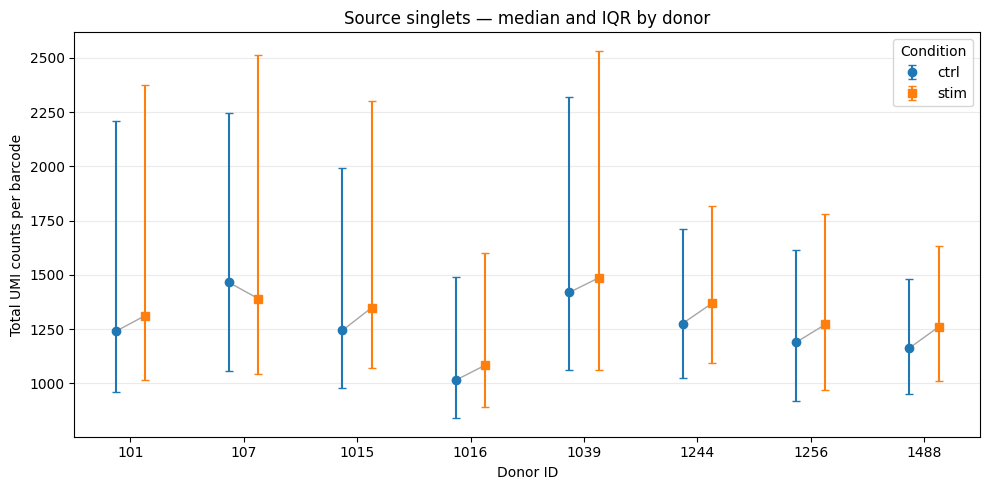

Saved: /kaggle/working/kang_ifnb/results/figures/stage03_donor_umi_singlets.png


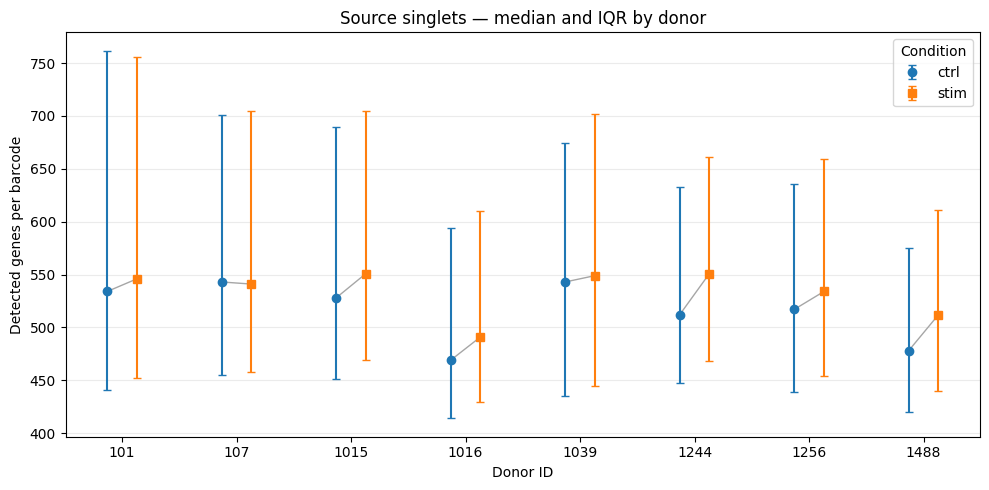

Saved: /kaggle/working/kang_ifnb/results/figures/stage03_donor_genes_singlets.png

DONOR-AWARE QC VISUALIZATION: PASS


In [7]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# Plot donor-specific medians and interquartile ranges
# --------------------------------------------------

def plot_donor_qc(summary, metric, ylabel, filename):

    center_col = f"{metric}_median"
    lower_col = f"{metric}_q25"
    upper_col = f"{metric}_q75"

    donors = sorted(
        summary["donor_id"].unique(),
        key=int,
    )

    def pivot_metric(column):
        return (
            summary.pivot(
                index="donor_id",
                columns="condition",
                values=column,
            )
            .loc[donors, ["ctrl", "stim"]]
        )

    median = pivot_metric(center_col)
    q25 = pivot_metric(lower_col)
    q75 = pivot_metric(upper_col)

    assert not median.isna().any().any()

    x = np.arange(len(donors))
    offset = 0.13

    fig, ax = plt.subplots(figsize=(10, 5))

    # Connect the two medians of the same donor
    for i in range(len(donors)):
        ax.plot(
            [x[i] - offset, x[i] + offset],
            [median.iloc[i]["ctrl"],
             median.iloc[i]["stim"]],
            color="0.65",
            linewidth=1,
            zorder=1,
        )

    # Condition-specific medians with IQR
    for condition, positions, marker in [
        ("ctrl", x - offset, "o"),
        ("stim", x + offset, "s"),
    ]:
        values = median[condition].to_numpy()

        errors = np.vstack([
            values - q25[condition].to_numpy(),
            q75[condition].to_numpy() - values,
        ])

        ax.errorbar(
            positions,
            values,
            yerr=errors,
            fmt=marker,
            capsize=3,
            label=condition,
            zorder=2,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(donors)
    ax.set_xlabel("Donor ID")
    ax.set_ylabel(ylabel)
    ax.set_title(
        "Source singlets — median and IQR by donor"
    )
    ax.legend(title="Condition")
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()

    output_path = FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


plot_donor_qc(
    qc_singlets,
    metric="umi",
    ylabel="Total UMI counts per barcode",
    filename="stage03_donor_umi_singlets.png",
)

plot_donor_qc(
    qc_singlets,
    metric="genes",
    ylabel="Detected genes per barcode",
    filename="stage03_donor_genes_singlets.png",
)

print("\nDONOR-AWARE QC VISUALIZATION: PASS")

## 5. Mitochondrial gene annotation and QC metrics

Audit mitochondrial gene candidates using source symbols and Ensembl IDs.


In [8]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Read original gene symbols
# --------------------------------------------------

symbols = (
    adata.var["gene_symbol"]
    .astype("string")
    .fillna("")
)

# --------------------------------------------------
# 2. Identify mitochondrial gene candidates
# --------------------------------------------------

mt_mask = symbols.str.startswith("MT-").to_numpy(
    dtype=bool
)

mt_genes = adata.var.loc[
    mt_mask, ["gene_symbol"]
].copy()

mt_genes.insert(
    0,
    "gene_id",
    mt_genes.index.astype(str),
)

# --------------------------------------------------
# 3. Validate candidates
# --------------------------------------------------

assert mt_mask.shape == (adata.n_vars,)
assert mt_mask.dtype == bool
assert mt_mask.sum() > 0, (
    "No MT- genes found; inspect gene annotation."
)

assert mt_genes["gene_id"].is_unique

# --------------------------------------------------
# 4. Inspect gene inventory
# --------------------------------------------------

print("Total genes:", adata.n_vars)
print("MT- candidate genes:", int(mt_mask.sum()))

print("\nMitochondrial gene candidates:")
display(mt_genes.reset_index(drop=True))

# --------------------------------------------------
# 5. Save candidate annotation
# --------------------------------------------------

mt_path = AUDIT_DIR / "stage03_mt_gene_candidates.tsv"

mt_genes.to_csv(
    mt_path,
    sep="\t",
    index=False,
)

print("\nSaved:", mt_path)
print("MITOCHONDRIAL CANDIDATE INVENTORY: PASS")

Total genes: 35635
MT- candidate genes: 13

Mitochondrial gene candidates:


,gene_id,gene_symbol
0,ENSG00000198888,MT-ND1
1,ENSG00000198763,MT-ND2
2,ENSG00000198804,MT-CO1
3,ENSG00000198712,MT-CO2
4,ENSG00000228253,MT-ATP8
5,ENSG00000198899,MT-ATP6
6,ENSG00000198938,MT-CO3
7,ENSG00000198840,MT-ND3
8,ENSG00000212907,MT-ND4L
9,ENSG00000198886,MT-ND4



Saved: /kaggle/working/kang_ifnb/results/audit/stage03_mt_gene_candidates.tsv
MITOCHONDRIAL CANDIDATE INVENTORY: PASS


In [9]:
from scipy import sparse

# --------------------------------------------------
# 1. Reference raw counts
# --------------------------------------------------

counts = adata.layers["counts"]

assert sparse.isspmatrix_csr(counts)
assert counts.dtype == np.int64
assert counts.shape == (29065, 35635)

# --------------------------------------------------
# 2. Calculate mitochondrial UMI counts
# --------------------------------------------------

mt_counts = np.asarray(
    counts[:, mt_mask].sum(axis=1)
).ravel().astype(np.int64)

total_counts = adata.obs[
    "total_counts"
].to_numpy(dtype=np.int64)

assert np.array_equal(
    total_counts,
    np.asarray(counts.sum(axis=1)).ravel()
)

# --------------------------------------------------
# 3. Calculate mitochondrial percentages
# --------------------------------------------------

pct_counts_mt = np.divide(
    mt_counts.astype(float) * 100.0,
    total_counts,
    out=np.full(adata.n_obs, np.nan),
    where=total_counts > 0,
)

# --------------------------------------------------
# 4. Validate results
# --------------------------------------------------

assert len(mt_counts) == adata.n_obs
assert len(pct_counts_mt) == adata.n_obs

assert np.all(mt_counts >= 0)
assert np.all(mt_counts <= total_counts)

valid = total_counts > 0

assert np.isfinite(pct_counts_mt[valid]).all()
assert (pct_counts_mt[valid] >= 0).all()
assert (pct_counts_mt[valid] <= 100).all()

assert np.isnan(pct_counts_mt[~valid]).all()

# No change to original raw-count matrix
assert counts.nnz == 17570845
assert int(counts.sum()) == 48600925

# --------------------------------------------------
# 5. Store annotation and QC metrics
# --------------------------------------------------

adata.var["mt"] = mt_mask

adata.obs["total_counts_mt"] = mt_counts
adata.obs["pct_counts_mt"] = pct_counts_mt

adata.uns["mitochondrial_qc_annotation"] = {
    "selection": "gene_symbol starts with MT-",
    "n_candidate_genes": int(mt_mask.sum()),
    "status": "candidate_annotation_pending_review",
}

# --------------------------------------------------
# 6. Descriptive summaries
# --------------------------------------------------

mt_summary = (
    adata.obs
    .groupby("source_sample_id", observed=True)
    .agg(
        n_barcodes=("pct_counts_mt", "size"),
        total_mt_umi=("total_counts_mt", "sum"),
        median_mt_pct=("pct_counts_mt", "median"),
        q25_mt_pct=("pct_counts_mt",
                    lambda x: x.quantile(0.25)),
        q75_mt_pct=("pct_counts_mt",
                    lambda x: x.quantile(0.75)),
        p95_mt_pct=("pct_counts_mt",
                    lambda x: x.quantile(0.95)),
        max_mt_pct=("pct_counts_mt", "max"),
    )
)

assert mt_summary["n_barcodes"].sum() == 29065

display(mt_summary)

print("\nOverall mitochondrial percentage:")
display(
    adata.obs["pct_counts_mt"].describe(
        percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

print("\nMITOCHONDRIAL QC METRICS: PASS")

,n_barcodes,total_mt_umi,median_mt_pct,q25_mt_pct,q75_mt_pct,p95_mt_pct,max_mt_pct
source_sample_id,,,,,,,
GSM2560248,14619,0,0.0,0.0,0.0,0.0,0.0
GSM2560249,14446,0,0.0,0.0,0.0,0.0,0.0



Overall mitochondrial percentage:


count    29065.0
mean         0.0
std          0.0
min          0.0
5%           0.0
25%          0.0
50%          0.0
75%          0.0
95%          0.0
99%          0.0
max          0.0
Name: pct_counts_mt, dtype: float64


MITOCHONDRIAL QC METRICS: PASS


### 5.1. Investigate absent mitochondrial counts

Trace zero mitochondrial counts back to the source matrices.


In [10]:
import json
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Locate mitochondrial genes
# --------------------------------------------------

counts = adata.layers["counts"]

mt_mask = adata.var["mt"].to_numpy(dtype=bool)
mt_indices = np.flatnonzero(mt_mask)

assert len(mt_indices) == 13

mt_audit = adata.var.iloc[mt_indices][
    ["gene_symbol"]
].copy()

# --------------------------------------------------
# 2. Independently count MT expression by sample
# --------------------------------------------------

sample_groups = {
    "ctrl": "GSM2560248",
    "stim": "GSM2560249",
}

for condition, accession in sample_groups.items():

    cell_mask = (
        adata.obs["source_sample_id"]
        .astype(str)
        .to_numpy() == accession
    )

    block = counts[cell_mask, :][:, mt_indices]

    mt_audit[f"{condition}_umi"] = (
        np.asarray(block.sum(axis=0))
        .ravel()
        .astype(np.int64)
    )

    mt_audit[f"{condition}_detected_barcodes"] = (
        np.asarray(block.getnnz(axis=0))
        .ravel()
        .astype(np.int64)
    )

    # Compare with per-cell calculations
    assert int(block.sum()) == int(
        adata.obs.loc[
            cell_mask, "total_counts_mt"
        ].sum()
    )

# --------------------------------------------------
# 3. Verify observed result
# --------------------------------------------------

umi_columns = ["ctrl_umi", "stim_umi"]

total_mt_umi = int(
    mt_audit[umi_columns].to_numpy().sum()
)

nonzero_mt_genes = int(
    (
        mt_audit[umi_columns].sum(axis=1) > 0
    ).sum()
)

print("Mitochondrial genes:", len(mt_audit))
print("MT genes with observed counts:", nonzero_mt_genes)
print("Total mitochondrial UMI:", total_mt_umi)

print("\nPer-gene audit:")
display(mt_audit)

# --------------------------------------------------
# 4. Check against global counts
# --------------------------------------------------

assert counts.nnz == 17570845
assert int(counts.sum()) == 48600925

# Verify whether MT rows are uniformly zero
assert total_mt_umi == 0
assert nonzero_mt_genes == 0

assert (
    mt_audit[
        ["ctrl_detected_barcodes",
         "stim_detected_barcodes"]
    ].to_numpy() == 0
).all()

# --------------------------------------------------
# 5. Document the QC limitation
# --------------------------------------------------

adata.uns["mitochondrial_qc_annotation"] = {
    "selection": "gene_symbol starts with MT-",
    "n_candidate_genes": 13,
    "n_genes_with_detected_counts": 0,
    "total_mt_umi": 0,
    "status": "uninformative_for_qc",
    "interpretation": (
        "All selected mitochondrial gene rows are zero "
        "in the supplied processed count matrix. "
        "Mitochondrial percentage cannot distinguish "
        "barcode quality in this dataset."
    ),
    "filtering_decision": (
        "Do not use mitochondrial percentage "
        "for cell filtering."
    ),
}

mt_audit.to_csv(
    AUDIT_DIR / "stage03_mt_zero_count_audit.tsv",
    sep="\t",
)

(AUDIT_DIR / "stage03_mt_qc_limitation.json").write_text(
    json.dumps(
        adata.uns["mitochondrial_qc_annotation"],
        indent=2
    ) + "\n",
    encoding="utf-8",
)

print("\nMITOCHONDRIAL SOURCE AUDIT: PASS")
print("Mitochondrial fraction usable for QC: NO")
print("Cells removed: 0")
print("Genes removed: 0")

Mitochondrial genes: 13
MT genes with observed counts: 0
Total mitochondrial UMI: 0

Per-gene audit:


,gene_symbol,ctrl_umi,ctrl_detected_barcodes,stim_umi,stim_detected_barcodes
gene_id,,,,,
ENSG00000198888,MT-ND1,0,0,0,0
ENSG00000198763,MT-ND2,0,0,0,0
ENSG00000198804,MT-CO1,0,0,0,0
ENSG00000198712,MT-CO2,0,0,0,0
ENSG00000228253,MT-ATP8,0,0,0,0
ENSG00000198899,MT-ATP6,0,0,0,0
ENSG00000198938,MT-CO3,0,0,0,0
ENSG00000198840,MT-ND3,0,0,0,0
ENSG00000212907,MT-ND4L,0,0,0,0



MITOCHONDRIAL SOURCE AUDIT: PASS
Mitochondrial fraction usable for QC: NO
Cells removed: 0
Genes removed: 0


## 6. Joint QC assessment and demuxlet labels

Compare library size with gene detection across demuxlet label groups.


In [11]:
# --------------------------------------------------
# 1. Prepare cell-level QC information
# --------------------------------------------------

qc_view = adata.obs[
    [
        "source_sample_id",
        "condition",
        "donor_id",
        "demuxlet_class",
        "total_counts",
        "n_genes_by_counts",
    ]
].copy()

for col in [
    "condition",
    "donor_id",
    "demuxlet_class",
]:
    qc_view[col] = qc_view[col].astype(str)

assert len(qc_view) == 29065

# --------------------------------------------------
# 2. Inspect demuxlet distribution
# --------------------------------------------------

class_counts = pd.crosstab(
    qc_view["condition"],
    qc_view["demuxlet_class"],
).reindex(
    index=["ctrl", "stim"],
    columns=["singlet", "doublet", "ambs"],
    fill_value=0,
)

assert class_counts.to_numpy().sum() == 29065

assert class_counts["singlet"].sum() == 24679
assert class_counts["doublet"].sum() == 3169
assert class_counts["ambs"].sum() == 1217

assert class_counts.loc["ctrl"].sum() == 14619
assert class_counts.loc["stim"].sum() == 14446

print("Demuxlet class counts by condition:")
display(class_counts)

# --------------------------------------------------
# 3. Joint descriptive statistics
# --------------------------------------------------

qc_by_class = (
    qc_view
    .groupby(
        ["condition", "demuxlet_class"],
        observed=True,
    )
    .agg(
        n_barcodes=("total_counts", "size"),

        umi_p05=(
            "total_counts",
            lambda s: s.quantile(0.05),
        ),
        umi_median=("total_counts", "median"),
        umi_p95=(
            "total_counts",
            lambda s: s.quantile(0.95),
        ),

        genes_p05=(
            "n_genes_by_counts",
            lambda s: s.quantile(0.05),
        ),
        genes_median=(
            "n_genes_by_counts", "median"
        ),
        genes_p95=(
            "n_genes_by_counts",
            lambda s: s.quantile(0.95),
        ),
    )
    .reset_index()
)

assert len(qc_by_class) == 6
assert qc_by_class["n_barcodes"].sum() == 29065

print("\nQC metrics by condition and demuxlet:")
display(qc_by_class.round(2))

# --------------------------------------------------
# 4. Save audit tables
# --------------------------------------------------

class_counts.to_csv(
    AUDIT_DIR / "stage03_demuxlet_by_condition.tsv",
    sep="\t",
)

qc_by_class.to_csv(
    AUDIT_DIR / "stage03_qc_by_demuxlet.tsv",
    sep="\t",
    index=False,
)

print("\nDEMUXLET QC SUMMARY: PASS")

Demuxlet class counts by condition:


demuxlet_class,singlet,doublet,ambs
condition,,,
ctrl,12315,1598,706
stim,12364,1571,511



QC metrics by condition and demuxlet:


,condition,demuxlet_class,n_barcodes,umi_p05,umi_median,umi_p95,genes_p05,genes_median,genes_p95
0,ctrl,ambs,706,602.00,917.5,3284.5,228.00,408.0,1000.75
1,ctrl,doublet,1598,990.55,2296.5,4815.2,450.85,852.0,1375.45
2,ctrl,singlet,12315,691.70,1202.0,3366.9,347.00,507.0,1002.30
3,stim,ambs,511,639.00,990.0,3921.0,100.50,436.0,1036.50
4,stim,doublet,1571,1178.50,2427.0,5109.0,506.50,874.0,1339.00
5,stim,singlet,12364,737.00,1287.5,3660.7,356.00,530.0,985.85



DEMUXLET QC SUMMARY: PASS


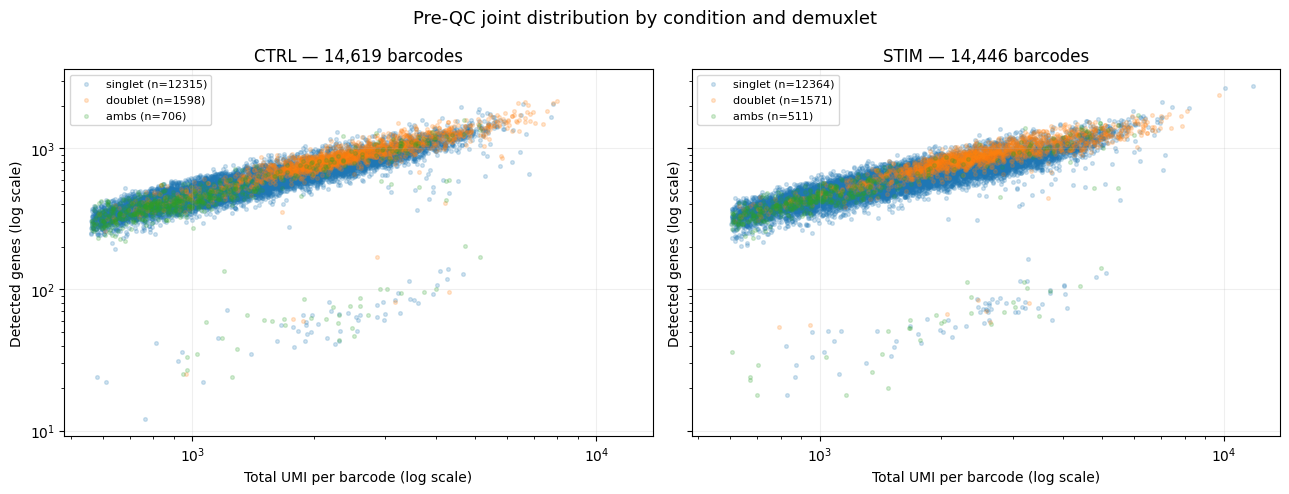


Ten barcodes with the fewest detected genes:


,source_sample_id,donor_id,condition,demuxlet_class,total_counts,n_genes_by_counts
cell_id,,,,,,
GSM2560248__GCCACTACAGGTTC-1,GSM2560248,1039,ctrl,singlet,763,12
GSM2560249__CATACTACATGTGC-1,GSM2560249,1039,stim,ambs,700,18
GSM2560249__CCATCCGATTTGGG-1,GSM2560249,1039,stim,ambs,1158,18
GSM2560249__GAGTACTGTATCGG-1,GSM2560249,1039,stim,singlet,829,18
GSM2560249__GGGCAGCTACTACG-1,GSM2560249,1256,stim,ambs,1477,20
GSM2560248__GATCTACTTTGACG-1,GSM2560248,1039,ctrl,singlet,1064,22
GSM2560248__TACCGAGATCACCC-1,GSM2560248,1039,ctrl,singlet,610,22
GSM2560249__ACTGTGGAAATCGC-1,GSM2560249,1039,stim,ambs,672,23
GSM2560248__TATCGTACAAGAAC-1,GSM2560248,1039,ctrl,ambs,1252,24



Saved: /kaggle/working/kang_ifnb/results/figures/stage03_joint_umi_genes_demuxlet.png
Cells removed: 0
Genes removed: 0

JOINT QC VISUALIZATION: PASS


In [12]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Verify plotting inputs
# --------------------------------------------------

assert (qc_view["total_counts"] > 0).all()
assert (qc_view["n_genes_by_counts"] > 0).all()

classes = ["singlet", "doublet", "ambs"]
conditions = ["ctrl", "stim"]

# --------------------------------------------------
# 2. Plot joint distributions
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True,
)

for ax, condition in zip(axes, conditions):

    condition_data = qc_view.loc[
        qc_view["condition"].eq(condition)
    ]

    for label in classes:

        subset = condition_data.loc[
            condition_data["demuxlet_class"].eq(label)
        ]

        ax.scatter(
            subset["total_counts"],
            subset["n_genes_by_counts"],
            s=7,
            alpha=0.20,
            label=f"{label} (n={len(subset)})",
            rasterized=True,
        )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_title(
        f"{condition.upper()} — {len(condition_data):,} barcodes"
    )

    ax.set_xlabel("Total UMI per barcode (log scale)")
    ax.set_ylabel("Detected genes (log scale)")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "Pre-QC joint distribution by condition and demuxlet",
    fontsize=13,
)

fig.tight_layout()

figure_path = (
    FIGURES_DIR
    / "stage03_joint_umi_genes_demuxlet.png"
)

fig.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# --------------------------------------------------
# 3. Inspect lowest detected-gene barcodes
# --------------------------------------------------

lowest_genes = (
    qc_view
    .nsmallest(10, "n_genes_by_counts")
    [
        [
            "source_sample_id",
            "donor_id",
            "condition",
            "demuxlet_class",
            "total_counts",
            "n_genes_by_counts",
        ]
    ]
)

print("\nTen barcodes with the fewest detected genes:")
display(lowest_genes)

# --------------------------------------------------
# 4. Verify dataset remains unchanged
# --------------------------------------------------

assert adata.n_obs == 29065
assert adata.n_vars == 35635

assert adata.layers["counts"].nnz == 17570845

assert int(
    adata.layers["counts"].sum()
) == 48600925

print("\nSaved:", figure_path)
print("Cells removed: 0")
print("Genes removed: 0")
print("\nJOINT QC VISUALIZATION: PASS")

## 7. Investigate low-complexity barcode populations

Review the low-complexity tail and its gene counts.


In [13]:
import numpy as np
import pandas as pd
import json

# --------------------------------------------
# 1. Prepare QC metadata
# --------------------------------------------

qc_diag = adata.obs[
    [
        "donor_id",
        "condition",
        "demuxlet_class",
        "cell_type_reference",
        "total_counts",
        "n_genes_by_counts",
    ]
].copy()

for col in ["donor_id", "condition", "demuxlet_class"]:
    qc_diag[col] = qc_diag[col].astype(str)

qc_diag["low_genes_50"] = (
    qc_diag["n_genes_by_counts"] <= 50
)

qc_diag["low_genes_100"] = (
    qc_diag["n_genes_by_counts"] <= 100
)

# --------------------------------------------
# 2. Summarize by donor and condition
# --------------------------------------------

def summarize_low_genes(frame):
    result = (
        frame.groupby(
            ["donor_id", "condition"],
            observed=True,
        )
        .agg(
            n_barcodes=("total_counts", "size"),
            n_le_50=("low_genes_50", "sum"),
            n_le_100=("low_genes_100", "sum"),
        )
        .reset_index()
    )

    result["pct_le_100"] = (
        100 * result["n_le_100"]
        / result["n_barcodes"]
    )

    return result


low_all = summarize_low_genes(qc_diag)

low_singlets = summarize_low_genes(
    qc_diag.loc[
        qc_diag["demuxlet_class"].eq("singlet")
    ]
)

assert len(low_all) == 16
assert len(low_singlets) == 16
assert low_all["n_barcodes"].sum() == 29065
assert low_singlets["n_barcodes"].sum() == 24679

print("All source barcodes:")
display(low_all)

print("\nSource singlets only:")
display(low_singlets)

# --------------------------------------------
# 3. Inspect reference labels in low-gene group
# --------------------------------------------

low_mask = qc_diag["low_genes_100"]

low_reference = pd.crosstab(
    qc_diag.loc[
        low_mask, "cell_type_reference"
    ].astype("string").fillna("Missing source label"),
    qc_diag.loc[
        low_mask, "demuxlet_class"
    ],
).reindex(
    columns=["singlet", "doublet", "ambs"],
    fill_value=0,
)

print("\nCell-type reference labels for <=100 genes:")
display(low_reference)

# --------------------------------------------
# 4. Save exploratory audits
# --------------------------------------------

low_all.to_csv(
    AUDIT_DIR / "stage03_low_genes_all.tsv",
    sep="\t",
    index=False,
)

low_singlets.to_csv(
    AUDIT_DIR / "stage03_low_genes_singlets.tsv",
    sep="\t",
    index=False,
)

low_reference.to_csv(
    AUDIT_DIR / "stage03_low_genes_reference_labels.tsv",
    sep="\t",
)

exploration_record = {
    "exploratory_gene_cutoffs": [50, 100],
    "purpose": "Characterize the low-complexity tail",
    "used_for_cell_filtering": False,
}

(
    AUDIT_DIR / "stage03_low_genes_exploration.json"
).write_text(
    json.dumps(exploration_record, indent=2) + "\n",
    encoding="utf-8",
)

assert adata.n_obs == 29065
assert adata.n_vars == 35635

print("\nLOW-COMPLEXITY DISTRIBUTION: PASS")

All source barcodes:


,donor_id,condition,n_barcodes,n_le_50,n_le_100,pct_le_100
0,101,ctrl,1027,3,5,0.486855
1,101,stim,1363,0,1,0.073368
2,1015,ctrl,3138,0,2,0.063735
3,1015,stim,2703,0,1,0.036996
4,1016,ctrl,2180,1,2,0.091743
5,1016,stim,1998,0,0,0.000000
6,1039,ctrl,552,22,67,12.137681
7,1039,stim,797,23,77,9.661230
8,107,ctrl,645,0,3,0.465116
9,107,stim,641,2,2,0.312012



Source singlets only:


,donor_id,condition,n_barcodes,n_le_50,n_le_100,pct_le_100
0,101,ctrl,858,0,0,0.000000
1,101,stim,1166,0,0,0.000000
2,1015,ctrl,2738,0,0,0.000000
3,1015,stim,2352,0,0,0.000000
4,1016,ctrl,1723,0,0,0.000000
5,1016,stim,1635,0,0,0.000000
6,1039,ctrl,461,17,47,10.195228
7,1039,stim,647,17,56,8.655332
8,107,ctrl,517,0,0,0.000000
9,107,stim,525,0,0,0.000000



Cell-type reference labels for <=100 genes:


demuxlet_class,singlet,doublet,ambs
cell_type_reference,,,
B cells,2,1,6
CD14+ Monocytes,24,3,21
CD4 T cells,16,3,4
CD8 T cells,2,0,0
Dendritic cells,0,0,4
FCGR3A+ Monocytes,6,0,2
Megakaryocytes,45,5,12
Missing source label,6,0,3
NK cells,2,0,4



LOW-COMPLEXITY DISTRIBUTION: PASS


In [14]:
from scipy import sparse

counts = adata.layers["counts"]

assert sparse.isspmatrix_csr(counts)

# --------------------------------------------
# 1. Select the ten lowest-gene barcodes
# --------------------------------------------

lowest_ids = (
    adata.obs["n_genes_by_counts"]
    .nsmallest(10)
    .index
)

summary_records = []
top_gene_records = []

# --------------------------------------------
# 2. Inspect their gene counts
# --------------------------------------------

for cell_id in lowest_ids:

    row_idx = adata.obs_names.get_loc(cell_id)
    row = counts.getrow(row_idx)

    gene_indices = row.indices
    gene_counts = row.data

    # Descending UMI counts, with stable gene-index tie break
    ranked = np.lexsort(
        (gene_indices, -gene_counts)
    )

    top_positions = ranked[:5]

    total_umi = int(gene_counts.sum())

    assert total_umi == int(
        adata.obs.loc[cell_id, "total_counts"]
    )

    assert len(gene_counts) == int(
        adata.obs.loc[cell_id, "n_genes_by_counts"]
    )

    top1_umi = int(
        gene_counts[top_positions[0]]
    )

    top5_umi = int(
        gene_counts[top_positions].sum()
    )

    summary_records.append({
        "cell_id": cell_id,
        "donor_id": str(
            adata.obs.loc[cell_id, "donor_id"]
        ),
        "condition": str(
            adata.obs.loc[cell_id, "condition"]
        ),
        "demuxlet_class": str(
            adata.obs.loc[cell_id, "demuxlet_class"]
        ),
        "cell_type_reference": str(
            adata.obs.loc[
                cell_id, "cell_type_reference"
            ]
        ),
        "total_umi": total_umi,
        "detected_genes": len(gene_counts),
        "top1_pct": 100 * top1_umi / total_umi,
        "top5_pct": 100 * top5_umi / total_umi,
    })

    for rank, position in enumerate(
        top_positions, start=1
    ):
        gene_idx = int(
            gene_indices[position]
        )

        umi = int(gene_counts[position])

        top_gene_records.append({
            "cell_id": cell_id,
            "rank": rank,
            "gene_id": str(
                adata.var_names[gene_idx]
            ),
            "gene_symbol": str(
                adata.var.iloc[gene_idx]["gene_symbol"]
            ),
            "umi": umi,
            "pct_of_cell_umi": 100 * umi / total_umi,
        })

# --------------------------------------------
# 3. Display results
# --------------------------------------------

low_complexity_detail = pd.DataFrame(
    summary_records
)

top_genes_detail = pd.DataFrame(
    top_gene_records
)

print("Low-complexity barcode summary:")
display(
    low_complexity_detail.round(2)
)

print("\nTop five genes per barcode:")
display(
    top_genes_detail.round(2)
)

# --------------------------------------------
# 4. Save evidence
# --------------------------------------------

low_complexity_detail.to_csv(
    AUDIT_DIR / "stage03_low_complexity_detail.tsv",
    sep="\t",
    index=False,
)

top_genes_detail.to_csv(
    AUDIT_DIR / "stage03_low_complexity_top_genes.tsv",
    sep="\t",
    index=False,
)

# --------------------------------------------
# 5. Verify counts remain unchanged
# --------------------------------------------

assert counts.shape == (29065, 35635)
assert counts.nnz == 17570845
assert int(counts.sum()) == 48600925

print("\nLOW-COMPLEXITY GENE INSPECTION: PASS")
print("Cells removed: 0")
print("Genes removed: 0")

Low-complexity barcode summary:


,cell_id,donor_id,condition,demuxlet_class,cell_type_reference,total_umi,detected_genes,top1_pct,top5_pct
0,GSM2560248__GCCACTACAGGTTC-1,1039,ctrl,singlet,Megakaryocytes,763,12,86.50,99.08
1,GSM2560249__CATACTACATGTGC-1,1039,stim,ambs,B cells,700,18,80.00,98.00
2,GSM2560249__CCATCCGATTTGGG-1,1039,stim,ambs,B cells,1158,18,75.13,98.70
3,GSM2560249__GAGTACTGTATCGG-1,1039,stim,singlet,Megakaryocytes,829,18,69.96,98.31
4,GSM2560249__GGGCAGCTACTACG-1,1256,stim,ambs,Megakaryocytes,1477,20,79.42,98.92
5,GSM2560248__GATCTACTTTGACG-1,1039,ctrl,singlet,CD14+ Monocytes,1064,22,72.93,98.21
6,GSM2560248__TACCGAGATCACCC-1,1039,ctrl,singlet,FCGR3A+ Monocytes,610,22,78.36,96.89
7,GSM2560249__ACTGTGGAAATCGC-1,1039,stim,ambs,CD14+ Monocytes,672,23,76.34,97.17
8,GSM2560248__TATCGTACAAGAAC-1,1039,ctrl,ambs,FCGR3A+ Monocytes,1252,24,72.84,98.40
9,GSM2560248__TCAGCGCTAAGCCT-1,1039,ctrl,singlet,CD4 T cells,582,24,77.66,96.56



Top five genes per barcode:


,cell_id,rank,gene_id,gene_symbol,umi,pct_of_cell_umi
0,GSM2560248__GCCACTACAGGTTC-1,1,ENSG00000244734,HBB,660,86.50
1,GSM2560248__GCCACTACAGGTTC-1,2,ENSG00000188536,HBA2,79,10.35
2,GSM2560248__GCCACTACAGGTTC-1,3,ENSG00000206172,HBA1,11,1.44
3,GSM2560248__GCCACTACAGGTTC-1,4,ENSG00000065978,YBX1,4,0.52
4,GSM2560248__GCCACTACAGGTTC-1,5,ENSG00000251562,MALAT1,2,0.26
5,GSM2560249__CATACTACATGTGC-1,1,ENSG00000244734,HBB,560,80.00
6,GSM2560249__CATACTACATGTGC-1,2,ENSG00000188536,HBA2,79,11.29
7,GSM2560249__CATACTACATGTGC-1,3,ENSG00000206172,HBA1,43,6.14
8,GSM2560249__CATACTACATGTGC-1,4,ENSG00000166710,B2M,2,0.29
9,GSM2560249__CATACTACATGTGC-1,5,ENSG00000170315,UBB,2,0.29



LOW-COMPLEXITY GENE INSPECTION: PASS
Cells removed: 0
Genes removed: 0


### 7.1. Hemoglobin-dominance diagnostics

Summarize the fraction of UMIs from HBB, HBA1 and HBA2.


In [15]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Define three genes verified in the source
# --------------------------------------------------

hb_genes = {
    "HBB": "ENSG00000244734",
    "HBA1": "ENSG00000206172",
    "HBA2": "ENSG00000188536",
}

for symbol, gene_id in hb_genes.items():
    assert gene_id in adata.var_names
    assert adata.var.loc[gene_id, "gene_symbol"] == symbol

gene_indices = adata.var_names.get_indexer(
    list(hb_genes.values())
)

assert (gene_indices >= 0).all()

# --------------------------------------------------
# 2. Calculate HB3 counts and fractions
# --------------------------------------------------

counts = adata.layers["counts"]

hb3_umi = np.asarray(
    counts[:, gene_indices].sum(axis=1)
).ravel().astype(np.int64)

total_umi = adata.obs[
    "total_counts"
].to_numpy(dtype=np.int64)

hb3_pct = np.divide(
    hb3_umi * 100.0,
    total_umi,
    out=np.full(adata.n_obs, np.nan),
    where=total_umi > 0,
)

assert np.all(hb3_umi >= 0)
assert np.all(hb3_umi <= total_umi)
assert np.all((hb3_pct >= 0) & (hb3_pct <= 100))

adata.obs["hb3_umi"] = hb3_umi
adata.obs["hb3_pct"] = hb3_pct

# --------------------------------------------------
# 3. Prepare exploratory flags
# --------------------------------------------------

qc_hb = adata.obs[
    [
        "donor_id",
        "condition",
        "demuxlet_class",
        "cell_type_reference",
        "n_genes_by_counts",
        "hb3_pct",
    ]
].copy()

qc_hb["low_genes_100"] = (
    qc_hb["n_genes_by_counts"] <= 100
)

qc_hb["hb3_ge_90"] = (
    qc_hb["hb3_pct"] >= 90
)

qc_hb["low100_hb90"] = (
    qc_hb["low_genes_100"] & qc_hb["hb3_ge_90"]
)

# Check against previously reported results
assert int(qc_hb["low_genes_100"].sum()) == 171

assert int(
    qc_hb.loc[
        qc_hb["demuxlet_class"].eq("singlet"),
        "low_genes_100",
    ].sum()
) == 103

# --------------------------------------------------
# 4. Check the ten extreme barcodes
# --------------------------------------------------

lowest_ids = (
    adata.obs["n_genes_by_counts"]
    .nsmallest(10)
    .index
)

top10_hb = qc_hb.loc[
    lowest_ids,
    [
        "donor_id",
        "condition",
        "n_genes_by_counts",
        "hb3_pct",
    ],
]

assert (top10_hb["hb3_pct"] > 95).all()

print("Hemoglobin fractions in 10 extreme barcodes:")
display(top10_hb.round(2))

# --------------------------------------------------
# 5. Summarize by donor and condition
# --------------------------------------------------

def summarize_hb(frame):
    return (
        frame.groupby(
            ["donor_id", "condition"],
            observed=True,
        )
        .agg(
            n_barcodes=("hb3_pct", "size"),
            n_low100=("low_genes_100", "sum"),
            n_hb90=("hb3_ge_90", "sum"),
            n_low100_hb90=("low100_hb90", "sum"),
            median_hb_pct=("hb3_pct", "median"),
            p95_hb_pct=(
                "hb3_pct",
                lambda x: x.quantile(0.95),
            ),
        )
        .reset_index()
    )

hb_by_donor = summarize_hb(qc_hb)

assert len(hb_by_donor) == 16
assert hb_by_donor["n_barcodes"].sum() == 29065

print("\nAll barcodes by donor-condition:")
display(hb_by_donor.round(2))

# --------------------------------------------------
# 6. Focus on primary-analysis cell type
# --------------------------------------------------

cd14_singlets = qc_hb.loc[
    qc_hb["demuxlet_class"].eq("singlet")
    & qc_hb["cell_type_reference"].eq("CD14+ Monocytes")
]

hb_cd14 = summarize_hb(cd14_singlets)

assert len(hb_cd14) == 16
assert int(hb_cd14["n_low100"].sum()) == 24

print("\nCD14+ Monocyte source singlets:")
display(hb_cd14.round(2))

# --------------------------------------------------
# 7. Save diagnostic summaries
# --------------------------------------------------

hb_by_donor.to_csv(
    AUDIT_DIR / "stage03_hb_by_donor_condition.tsv",
    sep="\t",
    index=False,
)

hb_cd14.to_csv(
    AUDIT_DIR / "stage03_hb_cd14_singlets.tsv",
    sep="\t",
    index=False,
)

# Original count matrix remains unchanged
assert counts.shape == (29065, 35635)
assert counts.nnz == 17570845
assert int(counts.sum()) == 48600925

print("\nHEMOGLOBIN DIAGNOSTICS: PASS")
print("Cells removed: 0")
print("Genes removed: 0")

Hemoglobin fractions in 10 extreme barcodes:


,donor_id,condition,n_genes_by_counts,hb3_pct
cell_id,,,,
GSM2560248__GCCACTACAGGTTC-1,1039,ctrl,12,98.30
GSM2560249__CATACTACATGTGC-1,1039,stim,18,97.43
GSM2560249__CCATCCGATTTGGG-1,1039,stim,18,98.01
GSM2560249__GAGTACTGTATCGG-1,1039,stim,18,97.83
GSM2560249__GGGCAGCTACTACG-1,1256,stim,20,98.44
GSM2560248__GATCTACTTTGACG-1,1039,ctrl,22,97.37
GSM2560248__TACCGAGATCACCC-1,1039,ctrl,22,96.07
GSM2560249__ACTGTGGAAATCGC-1,1039,stim,23,95.83
GSM2560248__TATCGTACAAGAAC-1,1039,ctrl,24,98.08



All barcodes by donor-condition:


,donor_id,condition,n_barcodes,n_low100,n_hb90,n_low100_hb90,median_hb_pct,p95_hb_pct
0,101,ctrl,1027,5,5,5,0.0,0.08
1,101,stim,1363,1,1,1,0.0,0.08
2,1015,ctrl,3138,2,2,2,0.0,0.08
3,1015,stim,2703,1,1,1,0.0,0.08
4,1016,ctrl,2180,2,2,2,0.0,0.10
5,1016,stim,1998,0,0,0,0.0,0.10
6,1039,ctrl,552,67,68,61,0.0,95.88
7,1039,stim,797,77,80,70,0.0,95.71
8,107,ctrl,645,3,3,3,0.0,0.07
9,107,stim,641,2,2,2,0.0,0.07



CD14+ Monocyte source singlets:


,donor_id,condition,n_barcodes,n_low100,n_hb90,n_low100_hb90,median_hb_pct,p95_hb_pct
0,101,ctrl,202,0,0,0,0.0,0.05
1,101,stim,253,0,0,0,0.0,0.07
2,1015,ctrl,779,0,0,0,0.0,0.06
3,1015,stim,671,0,0,0,0.0,0.06
4,1016,ctrl,369,0,0,0,0.0,0.08
5,1016,stim,329,0,0,0,0.0,0.07
6,1039,ctrl,126,12,13,11,0.0,96.00
7,1039,stim,165,12,13,11,0.0,95.03
8,107,ctrl,209,0,0,0,0.0,0.06
9,107,stim,169,0,0,0,0.0,0.06



HEMOGLOBIN DIAGNOSTICS: PASS
Cells removed: 0
Genes removed: 0


### 7.2. CD14+ marker review and hypothetical QC impact

Compare monocyte marker detection and inspect exclusions by donor and condition.


In [16]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Select source CD14+ singlets
# --------------------------------------------------

cd14_mask = (
    adata.obs["demuxlet_class"].astype(str).eq("singlet")
    & adata.obs["cell_type_reference"]
        .astype(str).eq("CD14+ Monocytes")
)

cd14 = adata.obs.loc[cd14_mask, [
    "donor_id",
    "condition",
    "total_counts",
    "n_genes_by_counts",
    "hb3_pct",
]].copy()

assert len(cd14) == 5385

# --------------------------------------------------
# 2. Locate marker genes by source annotations
# --------------------------------------------------

markers = [
    "CD14", "FCN1", "VCAN",
    "S100A8", "S100A9", "LYZ",
]

symbols = adata.var["gene_symbol"].astype(str)
marker_indices = []

for marker in markers:
    positions = np.flatnonzero(
        symbols.to_numpy() == marker
    )

    assert len(positions) == 1, (
        f"Review gene mapping for {marker}: "
        f"{len(positions)} matches"
    )

    marker_indices.append(int(positions[0]))

# --------------------------------------------------
# 3. Extract only six marker columns
# --------------------------------------------------

row_indices = adata.obs_names.get_indexer(
    cd14.index
)

marker_block = adata.layers["counts"][
    row_indices, :
][:, marker_indices]

# Only 5385 x 6 values are materialized,
# not the full count matrix.
marker_detected = (
    marker_block.toarray() > 0
)

cd14["n_markers_detected"] = (
    marker_detected.sum(axis=1)
)

for j, marker in enumerate(markers):
    cd14[f"{marker}_detected"] = (
        marker_detected[:, j]
    )

# --------------------------------------------------
# 4. Exploratory flags, NOT filtering rules
# --------------------------------------------------

cd14["hb90"] = cd14["hb3_pct"] >= 90

cd14["low100"] = (
    cd14["n_genes_by_counts"] <= 100
)

assert int(cd14["hb90"].sum()) == 26
assert int(cd14["low100"].sum()) == 24

assert int(
    (cd14["hb90"] & cd14["low100"]).sum()
) == 22

# Original object unchanged
assert adata.shape == (29065, 35635)

print("CD14+ source singlets:", len(cd14))
print("HB3 >=90%:", int(cd14["hb90"].sum()))
print("Detected genes <=100:", int(cd14["low100"].sum()))

print("\nMONOCYTE MARKER EXTRACTION: PASS")

CD14+ source singlets: 5385
HB3 >=90%: 26
Detected genes <=100: 24

MONOCYTE MARKER EXTRACTION: PASS


In [17]:
# --------------------------------------------------
# 1. Marker review within donor 1039
# --------------------------------------------------

d1039 = cd14.loc[
    cd14["donor_id"].astype(str).eq("1039")
].copy()

marker_review = (
    d1039.groupby(
        ["condition", "hb90"],
        observed=True,
    )
    .agg(
        n_barcodes=("hb3_pct", "size"),
        median_umi=("total_counts", "median"),
        median_genes=("n_genes_by_counts", "median"),
        median_hb_pct=("hb3_pct", "median"),
        median_markers=(
            "n_markers_detected", "median"
        ),
        pct_with_any_marker=(
            "n_markers_detected",
            lambda s: 100 * (s > 0).mean(),
        ),
    )
    .reset_index()
)

print("Donor 1039: HB-dominant vs other CD14+ singlets")
display(marker_review.round(2))

# --------------------------------------------------
# 2. Hypothetical effect by donor-condition
# --------------------------------------------------

impact = (
    cd14.groupby(
        ["donor_id", "condition"],
        observed=True,
    )
    .agg(
        n_before=("hb90", "size"),
        n_hb90=("hb90", "sum"),
        n_low100=("low100", "sum"),
    )
    .reset_index()
)

impact["n_after_if_hb90_excluded"] = (
    impact["n_before"] - impact["n_hb90"]
)

impact["pct_flagged_hb90"] = (
    100 * impact["n_hb90"] / impact["n_before"]
)

assert len(impact) == 16
assert impact["n_before"].sum() == 5385
assert impact["n_hb90"].sum() == 26
assert impact["n_after_if_hb90_excluded"].sum() == 5359

# Ensure hypothetical exclusions do not remove
# an entire donor-condition group
assert (
    impact["n_after_if_hb90_excluded"] > 0
).all()

print("\nHypothetical HB3 >=90% exclusion:")
display(impact.round(2))

# --------------------------------------------------
# 3. Inspect individual flagged barcodes
# --------------------------------------------------

flagged = cd14.loc[
    cd14["hb90"],
    [
        "donor_id", "condition",
        "total_counts", "n_genes_by_counts",
        "hb3_pct", "n_markers_detected",
    ],
].sort_values(["condition", "hb3_pct"])

print("\nHB-dominant CD14+ singlets:")
display(flagged.round(2))

# --------------------------------------------------
# 4. Save evidence without filtering
# --------------------------------------------------

marker_review.to_csv(
    AUDIT_DIR / "stage03_cd14_marker_review.tsv",
    sep="\t", index=False
)

impact.to_csv(
    AUDIT_DIR / "stage03_cd14_hb90_impact.tsv",
    sep="\t", index=False
)

flagged.to_csv(
    AUDIT_DIR / "stage03_cd14_hb90_flagged.tsv",
    sep="\t"
)

assert adata.n_obs == 29065
assert adata.n_vars == 35635
assert int(adata.layers["counts"].sum()) == 48600925

print("\nCD14 QC IMPACT ASSESSMENT: PASS")
print("Cells actually removed: 0")

Donor 1039: HB-dominant vs other CD14+ singlets


,condition,hb90,n_barcodes,median_umi,median_genes,median_hb_pct,median_markers,pct_with_any_marker
0,ctrl,False,113,2406.0,725.0,0.00,4.0,99.12
1,ctrl,True,13,2555.0,61.0,96.12,0.0,15.38
2,stim,False,152,2611.5,677.0,0.00,3.0,96.05
3,stim,True,13,2621.0,74.0,96.03,0.0,7.69



Hypothetical HB3 >=90% exclusion:


,donor_id,condition,n_before,n_hb90,n_low100,n_after_if_hb90_excluded,pct_flagged_hb90
0,101,ctrl,202,0,0,202,0.00
1,101,stim,253,0,0,253,0.00
2,1015,ctrl,779,0,0,779,0.00
3,1015,stim,671,0,0,671,0.00
4,1016,ctrl,369,0,0,369,0.00
5,1016,stim,329,0,0,329,0.00
6,1039,ctrl,126,13,12,113,10.32
7,1039,stim,165,13,12,152,7.88
8,107,ctrl,209,0,0,209,0.00
9,107,stim,169,0,0,169,0.00



HB-dominant CD14+ singlets:


,donor_id,condition,total_counts,n_genes_by_counts,hb3_pct,n_markers_detected
cell_id,,,,,,
GSM2560248__AGGGCGCTTACTGG-1,1039,ctrl,3165,84,90.24,0
GSM2560248__GCCATGCTAAACAG-1,1039,ctrl,4110,135,93.75,0
GSM2560248__CAAGGACTGCTAAC-1,1039,ctrl,4273,118,93.87,0
GSM2560248__GTCCACACCTTCGC-1,1039,ctrl,1662,56,94.58,0
GSM2560248__GTTGAGTGTAGCCA-1,1039,ctrl,2201,70,95.18,0
GSM2560248__ATCGGTGAATCGAC-1,1039,ctrl,1823,51,95.61,1
GSM2560248__TACATAGACTTAGG-1,1039,ctrl,1909,59,96.12,0
GSM2560248__GAACTGTGCAGAGG-1,1039,ctrl,2865,64,96.13,1
GSM2560248__TCTAACACACCACA-1,1039,ctrl,2566,61,96.34,0



CD14 QC IMPACT ASSESSMENT: PASS
Cells actually removed: 0


### 7.3. QC candidate sensitivity assessment

Compare 85%, 90% and 95% hemoglobin thresholds with the detected-gene criterion.


In [18]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Candidate QC flags: CD14+ source singlets
# --------------------------------------------------

assert len(cd14) == 5385

scenarios = {
    "HB3 >=85%": cd14["hb3_pct"] >= 85,
    "HB3 >=90%": cd14["hb3_pct"] >= 90,
    "HB3 >=95%": cd14["hb3_pct"] >= 95,
    "Genes <=100": cd14["n_genes_by_counts"] <= 100,
    "HB90 OR Genes<=100": (
        (cd14["hb3_pct"] >= 90)
        | (cd14["n_genes_by_counts"] <= 100)
    ),
}

assert int(scenarios["HB3 >=90%"].sum()) == 26
assert int(scenarios["Genes <=100"].sum()) == 24

# --------------------------------------------------
# 2. Summarize hypothetical exclusions
# --------------------------------------------------

results = []

for name, flagged in scenarios.items():

    working = cd14[
        ["donor_id", "condition"]
    ].copy()

    working["donor_id"] = working["donor_id"].astype(str)
    working["condition"] = working["condition"].astype(str)

    working["retained"] = ~flagged.to_numpy()

    remaining = (
        working.groupby(
            ["donor_id", "condition"]
        )["retained"]
        .sum()
    )

    assert len(remaining) == 16

    n_flagged = int(flagged.sum())

    results.append({
        "scenario": name,
        "n_flagged": n_flagged,
        "pct_flagged": 100 * n_flagged / len(cd14),
        "n_remaining": int((~flagged).sum()),
        "1039_ctrl_remaining": int(
            remaining.loc[("1039", "ctrl")]
        ),
        "1039_stim_remaining": int(
            remaining.loc[("1039", "stim")]
        ),
        "donor_condition_groups_retained": int(
            (remaining > 0).sum()
        ),
    })

sensitivity = pd.DataFrame(results)

print("Hypothetical QC sensitivity:")
display(sensitivity.round(2))

# --------------------------------------------------
# 3. Inspect disagreement between two criteria
# --------------------------------------------------

hb90 = cd14["hb3_pct"] >= 90
low100 = cd14["n_genes_by_counts"] <= 100

discordant = cd14.loc[
    hb90 != low100,
    [
        "donor_id",
        "condition",
        "total_counts",
        "n_genes_by_counts",
        "hb3_pct",
        "n_markers_detected",
    ],
].copy()

discordant["hb90_flag"] = hb90.loc[
    discordant.index
]

discordant["low100_flag"] = low100.loc[
    discordant.index
]

assert len(discordant) == 6

print("\nSix barcodes with discordant QC flags:")
display(
    discordant.sort_values(
        ["condition", "hb3_pct"]
    ).round(2)
)

# --------------------------------------------------
# 4. Save diagnostic results
# --------------------------------------------------

sensitivity.to_csv(
    AUDIT_DIR / "stage03_qc_candidate_sensitivity.tsv",
    sep="\t",
    index=False,
)

discordant.to_csv(
    AUDIT_DIR / "stage03_qc_discordant_flags.tsv",
    sep="\t",
)

# --------------------------------------------------
# 5. Verify original AnnData is unchanged
# --------------------------------------------------

assert adata.shape == (29065, 35635)
assert adata.layers["counts"].nnz == 17570845
assert int(adata.layers["counts"].sum()) == 48600925

print("\nQC CANDIDATE SENSITIVITY: PASS")
print("Cells actually removed: 0")
print("Genes actually removed: 0")

Hypothetical QC sensitivity:


,scenario,n_flagged,pct_flagged,n_remaining,1039_ctrl_remaining,1039_stim_remaining,donor_condition_groups_retained
0,HB3 >=85%,26,0.48,5359,113,152,16
1,HB3 >=90%,26,0.48,5359,113,152,16
2,HB3 >=95%,18,0.33,5367,117,156,16
3,Genes <=100,24,0.45,5361,114,153,16
4,HB90 OR Genes<=100,28,0.52,5357,112,151,16



Six barcodes with discordant QC flags:


,donor_id,condition,total_counts,n_genes_by_counts,hb3_pct,n_markers_detected,hb90_flag,low100_flag
cell_id,,,,,,,,
GSM2560248__TGTGGATGGGACAG-1,1039,ctrl,1897,43,81.13,1,False,True
GSM2560248__GCCATGCTAAACAG-1,1039,ctrl,4110,135,93.75,0,True,False
GSM2560248__CAAGGACTGCTAAC-1,1039,ctrl,4273,118,93.87,0,True,False
GSM2560249__CACAGAACTAACCG-1,1039,stim,1844,62,77.55,0,False,True
GSM2560249__ACCTATTGGTGCAT-1,1039,stim,3132,114,92.78,1,True,False
GSM2560249__TGACGAACAATGCC-1,1039,stim,4815,122,95.10,0,True,False



QC CANDIDATE SENSITIVITY: PASS
Cells actually removed: 0
Genes actually removed: 0


## 8. Record primary CD14+ QC decisions

Record the primary exclusions and their group-level impact.


In [19]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Define primary cohort using source annotations
# --------------------------------------------------

primary_mask = (
    adata.obs["demuxlet_class"].astype(str).eq("singlet")
    & adata.obs["cell_type_reference"]
        .astype(str).eq("CD14+ Monocytes")
)

primary_qc = adata.obs.loc[
    primary_mask,
    [
        "source_sample_id",
        "donor_id",
        "condition",
        "total_counts",
        "n_genes_by_counts",
        "hb3_pct",
    ],
].copy()

assert len(primary_qc) == 5385

# --------------------------------------------------
# 2. Define candidate QC exclusion flags
# --------------------------------------------------

primary_qc["flag_hb90"] = (
    primary_qc["hb3_pct"] >= 90
)

primary_qc["flag_low100"] = (
    primary_qc["n_genes_by_counts"] <= 100
)

primary_qc["flag_both"] = (
    primary_qc["flag_hb90"]
    & primary_qc["flag_low100"]
)

primary_qc["qc_exclude_candidate"] = (
    primary_qc["flag_hb90"]
    | primary_qc["flag_low100"]
)

# --------------------------------------------------
# 3. Assign mutually exclusive reasons
# --------------------------------------------------

primary_qc["qc_reason"] = np.select(
    [
        primary_qc["flag_both"],
        primary_qc["flag_hb90"],
        primary_qc["flag_low100"],
    ],
    [
        "hb90_and_low100",
        "hb90_only",
        "low100_only",
    ],
    default="retain",
)

# --------------------------------------------------
# 4. Verify overlap and exclusion counts
# --------------------------------------------------

assert int(primary_qc["flag_hb90"].sum()) == 26
assert int(primary_qc["flag_low100"].sum()) == 24
assert int(primary_qc["flag_both"].sum()) == 22

assert int(
    primary_qc["qc_exclude_candidate"].sum()
) == 28

assert int(
    (~primary_qc["qc_exclude_candidate"]).sum()
) == 5357

reason_counts = (
    primary_qc["qc_reason"]
    .value_counts()
)

assert reason_counts["hb90_and_low100"] == 22
assert reason_counts["hb90_only"] == 4
assert reason_counts["low100_only"] == 2
assert reason_counts["retain"] == 5357

print("Candidate primary QC reasons:")
display(reason_counts.rename("n_barcodes").to_frame())

print("\nPRIMARY QC FLAGS: PASS")

Candidate primary QC reasons:


,n_barcodes
qc_reason,
retain,5357
hb90_and_low100,22
hb90_only,4
low100_only,2



PRIMARY QC FLAGS: PASS


In [20]:
import json
from datetime import datetime, timezone

# --------------------------------------------------
# 1. Summarize decisions by donor-condition
# --------------------------------------------------

qc_impact = (
    primary_qc
    .groupby(
        ["donor_id", "condition"],
        observed=True,
    )
    .agg(
        n_before=("qc_reason", "size"),
        n_hb90=("flag_hb90", "sum"),
        n_low100=("flag_low100", "sum"),
        n_both=("flag_both", "sum"),
        n_excluded=("qc_exclude_candidate", "sum"),
    )
    .reset_index()
)

qc_impact["n_retained"] = (
    qc_impact["n_before"]
    - qc_impact["n_excluded"]
)

qc_impact["pct_excluded"] = (
    100 * qc_impact["n_excluded"]
    / qc_impact["n_before"]
)

# --------------------------------------------------
# 2. Verify cohort and pairing
# --------------------------------------------------

assert len(qc_impact) == 16
assert qc_impact["n_before"].sum() == 5385
assert qc_impact["n_excluded"].sum() == 28
assert qc_impact["n_retained"].sum() == 5357

assert (qc_impact["n_retained"] > 0).all()

donor1039 = qc_impact.loc[
    qc_impact["donor_id"].astype(str).eq("1039")
].set_index("condition")

assert int(donor1039.loc["ctrl", "n_retained"]) == 112
assert int(donor1039.loc["stim", "n_retained"]) == 151

print("Candidate QC impact by donor-condition:")
display(qc_impact)

# --------------------------------------------------
# 3. Save individual decisions
# --------------------------------------------------

primary_qc.to_csv(
    AUDIT_DIR / "stage03_primary_cd14_qc_flags.tsv.gz",
    sep="\t",
    index=True,
)

qc_impact.to_csv(
    AUDIT_DIR / "stage03_primary_cd14_qc_impact.tsv",
    sep="\t",
    index=False,
)

# --------------------------------------------------
# 4. Record methodological decision
# --------------------------------------------------

qc_policy = {
    "recorded_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": "candidate_primary_cohort",

    "source_cohort": {
        "demuxlet_class": "singlet",
        "cell_type_reference": "CD14+ Monocytes",
    },

    "exclusion_rule": {
        "logic": "OR",
        "hb3_pct_greater_equal": 90,
        "n_genes_by_counts_less_equal": 100,
    },

    "exclusion_counts": {
        "hb90_only": 4,
        "low100_only": 2,
        "both": 22,
        "union": 28,
    },

    "n_source_cd14_singlets": 5385,
    "n_candidate_retained": 5357,

    "mitochondrial_qc": (
        "Not used: all 13 candidate mitochondrial "
        "genes have zero counts in source data."
    ),

    "count_handling": (
        "Original integer UMI counts are unchanged."
    ),

    "decision_basis": (
        "Exploratory QC distributions, hemoglobin "
        "concentration, monocyte marker review and "
        "threshold sensitivity; selected before DE."
    ),

    "limitations": (
        "Source cell-type labels are not independently "
        "validated; this is not a universal QC cutoff."
    ),

    "planned_robustness": [
        "Compare with HB3 >=95%",
        "Evaluate donor 1039 influence",
        "Review cell-type marker consistency",
    ],
}

policy_path = (
    AUDIT_DIR / "stage03_primary_cd14_qc_policy.json"
)

policy_path.write_text(
    json.dumps(qc_policy, indent=2) + "\n",
    encoding="utf-8",
)

# --------------------------------------------------
# 5. Verify original counts are untouched
# --------------------------------------------------

assert adata.shape == (29065, 35635)
assert adata.layers["counts"].dtype == np.int64
assert adata.layers["counts"].nnz == 17570845
assert int(adata.layers["counts"].sum()) == 48600925

print("\nQC audit:", policy_path)
print("Donor-condition groups retained: 16")
print("Cells actually removed: 0")
print("Genes actually removed: 0")

print("\nPRIMARY CD14 QC POLICY AUDIT: PASS")

Candidate QC impact by donor-condition:


,donor_id,condition,n_before,n_hb90,n_low100,n_both,n_excluded,n_retained,pct_excluded
0,101,ctrl,202,0,0,0,0,202,0.000000
1,101,stim,253,0,0,0,0,253,0.000000
2,1015,ctrl,779,0,0,0,0,779,0.000000
3,1015,stim,671,0,0,0,0,671,0.000000
4,1016,ctrl,369,0,0,0,0,369,0.000000
5,1016,stim,329,0,0,0,0,329,0.000000
6,1039,ctrl,126,13,12,11,14,112,11.111111
7,1039,stim,165,13,12,11,14,151,8.484848
8,107,ctrl,209,0,0,0,0,209,0.000000
9,107,stim,169,0,0,0,0,169,0.000000



QC audit: /kaggle/working/kang_ifnb/results/audit/stage03_primary_cd14_qc_policy.json
Donor-condition groups retained: 16
Cells actually removed: 0
Genes actually removed: 0

PRIMARY CD14 QC POLICY AUDIT: PASS


## 9. Construct the candidate CD14+ analysis cohort

Validate the selected CD14+ cohort against the source count matrix.


In [21]:
import numpy as np
import pandas as pd
from scipy import sparse

# --------------------------------------------------
# 1. Select cell IDs passing the recorded policy
# --------------------------------------------------

keep_ids = primary_qc.index[
    ~primary_qc["qc_exclude_candidate"]
]

assert len(keep_ids) == 5357
assert keep_ids.is_unique

# All selected cells must exist in original AnnData
assert adata.obs_names.is_unique
assert keep_ids.isin(adata.obs_names).all()

# Verify selected order matches the original order
expected_order = adata.obs_names[
    adata.obs_names.isin(keep_ids)
]

assert keep_ids.tolist() == expected_order.tolist()

# --------------------------------------------------
# 2. Create independent AnnData object
# --------------------------------------------------

adata_cd14 = adata[keep_ids.tolist(), :].copy()

assert not adata_cd14.is_view

# --------------------------------------------------
# 3. Record cohort provenance
# --------------------------------------------------

adata_cd14.uns["cohort_definition"] = {
    "name": "CD14_monocytes_candidate_primary",
    "source_annotation": "CD14+ Monocytes",
    "demuxlet_class": "singlet",
    "qc_policy": (
        "Exclude HB3 >= 90% OR detected genes <= 100"
    ),
    "n_before_candidate_qc": 5385,
    "n_excluded_candidate_qc": 28,
    "n_retained": 5357,
    "status": "candidate_pre_DE",
    "counts": "unnormalized integer UMI",
    "gene_filtering_applied": False,
    "cell_type_review_pending": True,
}

# --------------------------------------------------
# 4. Initial checks
# --------------------------------------------------

assert adata_cd14.shape == (5357, 35635)

assert sparse.isspmatrix_csr(adata_cd14.X)
assert adata_cd14.X.dtype == np.int64

assert (
    sparse.isspmatrix_csr(
        adata_cd14.layers["counts"]
    )
)

assert adata_cd14.layers["counts"].dtype == np.int64

assert adata_cd14.raw is None

print(adata_cd14)
print("\nSource AnnData:", adata.shape)
print("Candidate CD14 cohort:", adata_cd14.shape)

print("\nCD14 CANDIDATE COHORT: PASS")

AnnData object with n_obs × n_vars = 5357 × 35635
    obs: 'source_sample_id', 'condition', 'matrix_column_zero_based', 'barcode_original', 'metadata_cell_id', 'source_tsne1', 'source_tsne2', 'donor_id', 'cluster_reference', 'cell_type_reference', 'demuxlet_class', 'total_counts', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'hb3_umi', 'hb3_pct'
    var: 'gene_symbol', 'mt'
    uns: 'provenance', 'mitochondrial_qc_annotation', 'cohort_definition'
    layers: 'counts', None (.X)

Source AnnData: (29065, 35635)
Candidate CD14 cohort: (5357, 35635)

CD14 CANDIDATE COHORT: PASS


In [22]:
# --------------------------------------------------
# 1. Verify exact cell and gene order
# --------------------------------------------------

assert (
    adata_cd14.obs_names.tolist()
    == keep_ids.tolist()
)

assert (
    adata_cd14.var_names.tolist()
    == adata.var_names.tolist()
)

assert adata_cd14.obs_names.is_unique
assert adata_cd14.var_names.is_unique


# --------------------------------------------------
# 2. Verify metadata, accounting for unused categories
# --------------------------------------------------

# Expected metadata from the original AnnData
expected_obs = adata.obs.loc[
    keep_ids, adata.obs.columns
].copy()

# Actual metadata in the selected cohort
actual_obs = adata_cd14.obs.loc[
    :, adata.obs.columns
].copy()

# AnnData removes unused categories when subsetting.
# Apply the same operation to expected metadata
# so categorical schemas can be compared consistently.
for col in expected_obs.columns:
    if isinstance(expected_obs[col].dtype, pd.CategoricalDtype):
        expected_obs[col] = (
            expected_obs[col]
            .cat.remove_unused_categories()
        )

# Compare all original metadata fields and their values
pd.testing.assert_frame_equal(
    actual_obs,
    expected_obs,
    check_exact=True,
)

# Gene metadata must remain unchanged
pd.testing.assert_frame_equal(
    adata_cd14.var,
    adata.var,
    check_exact=True,
)

print("Cell metadata values: EXACT MATCH")
print("Categorical unused levels: NORMALIZED FOR COMPARISON")
print("Gene metadata: EXACT MATCH")


# --------------------------------------------------
# 3. Compare selected counts with original AnnData
# --------------------------------------------------

source_positions = adata.obs_names.get_indexer(
    keep_ids
)

assert (source_positions >= 0).all()

expected_counts = adata.layers["counts"][
    source_positions, :
]

actual_counts = adata_cd14.layers["counts"]

assert actual_counts.shape == expected_counts.shape
assert actual_counts.dtype == expected_counts.dtype
assert actual_counts.nnz == expected_counts.nnz

# Exact comparison without converting to dense
assert (actual_counts != expected_counts).nnz == 0

# X and counts layer must still be identical
assert (
    adata_cd14.X != adata_cd14.layers["counts"]
).nnz == 0

# --------------------------------------------------
# 4. Validate donor-condition retention
# --------------------------------------------------

cohort_obs = adata_cd14.obs.copy()

cohort_obs["donor_id"] = (
    cohort_obs["donor_id"].astype(str)
)

cohort_obs["condition"] = (
    cohort_obs["condition"].astype(str)
)

cohort_pairs = (
    cohort_obs.groupby(
        ["donor_id", "condition"]
    )
    .size()
    .sort_index()
)

expected_pairs = (
    qc_impact
    .assign(
        donor_id=lambda x: x["donor_id"].astype(str),
        condition=lambda x: x["condition"].astype(str),
    )
    .set_index(["donor_id", "condition"])["n_retained"]
    .sort_index()
)

assert cohort_pairs.index.equals(expected_pairs.index)

assert np.array_equal(
    cohort_pairs.to_numpy(),
    expected_pairs.to_numpy(),
)

assert len(cohort_pairs) == 16
assert (cohort_pairs > 0).all()
assert int(cohort_pairs.sum()) == 5357

# --------------------------------------------------
# 5. Verify selected cohort composition
# --------------------------------------------------

assert (
    adata_cd14.obs["demuxlet_class"]
    .astype(str).eq("singlet").all()
)

assert (
    adata_cd14.obs["cell_type_reference"]
    .astype(str).eq("CD14+ Monocytes").all()
)

assert (
    adata_cd14.obs["hb3_pct"] < 90
).all()

assert (
    adata_cd14.obs["n_genes_by_counts"] > 100
).all()

# --------------------------------------------------
# 6. Verify original AnnData remains unchanged
# --------------------------------------------------

assert adata.shape == (29065, 35635)
assert adata.layers["counts"].nnz == 17570845
assert int(adata.layers["counts"].sum()) == 48600925

# --------------------------------------------------
# 7. Report actual cohort statistics
# --------------------------------------------------

print("Retained cells by donor-condition:")
display(
    cohort_pairs.rename("n_retained").unstack()
)

print("\nCandidate CD14 cohort:")
print("Cells:", adata_cd14.n_obs)
print("Genes:", adata_cd14.n_vars)
print("Nonzero count entries:", actual_counts.nnz)
print("Total UMI:", int(actual_counts.sum()))

print("\nOriginal AnnData:", adata.shape)
print("Original total UMI:", int(adata.layers["counts"].sum()))

print("\nCD14 COHORT INTEGRITY: PASS")

Cell metadata values: EXACT MATCH
Categorical unused levels: NORMALIZED FOR COMPARISON
Gene metadata: EXACT MATCH
Retained cells by donor-condition:


condition,ctrl,stim
donor_id,,
101,202,253
1015,779,671
1016,369,329
1039,112,151
107,209,169
1244,415,290
1256,390,375
1488,295,348



Candidate CD14 cohort:
Cells: 5357
Genes: 35635
Nonzero count entries: 3700565
Total UMI: 12580095

Original AnnData: (29065, 35635)
Original total UMI: 48600925

CD14 COHORT INTEGRITY: PASS


## 10. Pseudobulk readiness assessment

Check retained cell counts and library sizes for all donor–condition samples.


In [23]:

import numpy as np
import pandas as pd
from scipy import sparse

# --------------------------------------------------
# 1. Verify candidate cohort
# --------------------------------------------------

counts = adata_cd14.layers["counts"]

assert adata_cd14.shape == (5357, 35635)
assert sparse.isspmatrix_csr(counts)
assert counts.dtype == np.int64

assert counts.nnz == 3700565
assert int(counts.sum()) == 12580095

# --------------------------------------------------
# 2. Read donor-condition assignments
# --------------------------------------------------

donors = (
    adata_cd14.obs["donor_id"]
    .astype(str)
    .to_numpy()
)

conditions = (
    adata_cd14.obs["condition"]
    .astype(str)
    .to_numpy()
)

donor_ids = sorted(set(donors), key=int)

assert len(donor_ids) == 8
assert set(conditions) == {"ctrl", "stim"}

# --------------------------------------------------
# 3. Calculate sample-level QC summaries
# --------------------------------------------------

records = []

for donor in donor_ids:
    for condition in ["ctrl", "stim"]:

        rows = np.flatnonzero(
            (donors == donor)
            & (conditions == condition)
        )

        assert len(rows) > 0

        # Aggregate raw UMI counts across selected cells.
        # Only a vector of 35,635 genes is materialized.
        gene_sums = np.asarray(
            counts[rows, :].sum(axis=0)
        ).ravel()

        group_umi = int(gene_sums.sum())

        cell_metadata = adata_cd14.obs.iloc[rows]

        # Reconcile with existing per-cell QC metrics
        assert group_umi == int(
            cell_metadata["total_counts"].sum()
        )

        records.append({
            "donor_id": donor,
            "condition": condition,
            "sample_id": f"{donor}__{condition}",
            "n_cells": len(rows),
            "total_umi": group_umi,
            "median_umi_per_cell": float(
                cell_metadata["total_counts"].median()
            ),
            "median_genes_per_cell": float(
                cell_metadata["n_genes_by_counts"].median()
            ),
            "genes_with_1plus_umi": int(
                np.count_nonzero(gene_sums >= 1)
            ),
            "genes_with_10plus_umi": int(
                np.count_nonzero(gene_sums >= 10)
            ),
        })

sample_readiness = pd.DataFrame(records)

# --------------------------------------------------
# 4. Validate biological sample structure
# --------------------------------------------------

assert len(sample_readiness) == 16
assert sample_readiness["sample_id"].is_unique

assert sample_readiness["n_cells"].sum() == 5357
assert sample_readiness["total_umi"].sum() == 12580095

assert sample_readiness["n_cells"].min() == 112

assert (
    sample_readiness["genes_with_10plus_umi"]
    <= sample_readiness["genes_with_1plus_umi"]
).all()

assert (
    sample_readiness["genes_with_1plus_umi"]
    <= adata_cd14.n_vars
).all()

paired = sample_readiness.pivot(
    index="donor_id",
    columns="condition",
    values="n_cells",
).loc[donor_ids, ["ctrl", "stim"]]

assert paired.shape == (8, 2)
assert (paired > 0).all().all()

# --------------------------------------------------
# 5. Save reproducible audit
# --------------------------------------------------

output_path = (
    AUDIT_DIR
    / "stage03_cd14_pseudobulk_readiness.tsv"
)

sample_readiness.to_csv(
    output_path,
    sep="\t",
    index=False,
)

# --------------------------------------------------
# 6. Display results
# --------------------------------------------------

print("Sample-level pseudobulk readiness:")
display(sample_readiness)

print("\nPaired donor cell counts:")
display(paired)

print("\nTotal candidate CD14+ cells:",
      int(sample_readiness["n_cells"].sum()))

print("Total candidate CD14+ UMI:",
      int(sample_readiness["total_umi"].sum()))

print("Donor-condition units:", len(sample_readiness))
print("Paired donors:", len(paired))

print("\nAudit saved:", output_path)
print("Cells removed in this step: 0")
print("Genes removed in this step: 0")

print("\nPSEUDOBULK READINESS AUDIT: PASS")


Sample-level pseudobulk readiness:


,donor_id,condition,sample_id,n_cells,total_umi,median_umi_per_cell,median_genes_per_cell,genes_with_1plus_umi,genes_with_10plus_umi
0,101,ctrl,101__ctrl,202,524723,2537.5,798.5,9315,3592
1,101,stim,101__stim,253,726512,2829.0,781.0,9211,3608
2,107,ctrl,107__ctrl,209,469563,2161.0,662.0,8919,3107
3,107,stim,107__stim,169,436403,2584.0,681.0,7913,2539
4,1015,ctrl,1015__ctrl,779,1685517,2056.0,646.0,11439,6113
5,1015,stim,1015__stim,671,1681881,2496.0,682.0,10690,5082
6,1016,ctrl,1016__ctrl,369,721958,1892.0,657.0,10100,4293
7,1016,stim,1016__stim,329,707388,2057.0,650.0,9356,3606
8,1039,ctrl,1039__ctrl,112,270440,2419.5,725.5,7998,2240
9,1039,stim,1039__stim,151,426492,2624.0,677.0,8047,2514



Paired donor cell counts:


condition,ctrl,stim
donor_id,,
101,202,253
107,209,169
1015,779,671
1016,369,329
1039,112,151
1244,415,290
1256,390,375
1488,295,348



Total candidate CD14+ cells: 5357
Total candidate CD14+ UMI: 12580095
Donor-condition units: 16
Paired donors: 8

Audit saved: /kaggle/working/kang_ifnb/results/audit/stage03_cd14_pseudobulk_readiness.tsv
Cells removed in this step: 0
Genes removed in this step: 0

PSEUDOBULK READINESS AUDIT: PASS


## 11. Donor-aware CD14+ marker consistency

Compare six marker detection rates across all 16 groups.


In [24]:

import numpy as np
import pandas as pd
from scipy import sparse

# --------------------------------------------------
# 1. Define monocyte-associated markers
# --------------------------------------------------

markers = [
    "CD14",
    "FCN1",
    "VCAN",
    "S100A8",
    "S100A9",
    "LYZ",
]

symbols = (
    adata_cd14.var["gene_symbol"]
    .astype(str)
    .to_numpy()
)

marker_indices = []

for marker in markers:
    positions = np.flatnonzero(symbols == marker)

    assert len(positions) == 1, (
        f"Review marker annotation: {marker}; "
        f"matches={len(positions)}"
    )

    marker_indices.append(int(positions[0]))

# --------------------------------------------------
# 2. Extract raw counts of the six markers
# --------------------------------------------------

counts = adata_cd14.layers["counts"]

assert sparse.isspmatrix_csr(counts)
assert counts.dtype == np.int64

marker_counts = counts[:, marker_indices].toarray()

assert marker_counts.shape == (5357, 6)
assert np.all(marker_counts >= 0)

# True if marker has at least one UMI in the cell
detected = marker_counts > 0

# --------------------------------------------------
# 3. Construct cell-level diagnostic table
# --------------------------------------------------

marker_cell = adata_cd14.obs[
    ["donor_id", "condition"]
].copy()

marker_cell["donor_id"] = (
    marker_cell["donor_id"].astype(str)
)

marker_cell["condition"] = (
    marker_cell["condition"].astype(str)
)

for j, gene in enumerate(markers):
    marker_cell[f"detected_{gene}"] = detected[:, j]

marker_cell["n_markers_detected"] = (
    detected.sum(axis=1)
)

marker_cell["any_marker"] = (
    marker_cell["n_markers_detected"] > 0
)

assert len(marker_cell) == 5357

assert marker_cell["n_markers_detected"].between(
    0, 6
).all()

# --------------------------------------------------
# 4. Summarize by donor and condition
# --------------------------------------------------

grouped = marker_cell.groupby(
    ["donor_id", "condition"],
    observed=True,
)

marker_summary = grouped.agg(
    n_cells=("any_marker", "size"),

    pct_any_marker=(
        "any_marker",
        lambda x: 100 * x.mean(),
    ),

    median_n_markers=(
        "n_markers_detected", "median"
    ),

    **{
        f"pct_{gene}": (
            f"detected_{gene}",
            lambda x: 100 * x.mean(),
        )
        for gene in markers
    },
).reset_index()

# --------------------------------------------------
# 5. Check donor-condition alignment
# --------------------------------------------------

assert len(marker_summary) == 16

assert marker_summary["n_cells"].sum() == 5357

expected = (
    sample_readiness
    .assign(
        donor_id=lambda x: x["donor_id"].astype(str),
        condition=lambda x: x["condition"].astype(str),
    )
    .set_index(["donor_id", "condition"])["n_cells"]
    .sort_index()
)

observed = (
    marker_summary
    .set_index(["donor_id", "condition"])["n_cells"]
    .sort_index()
)

pd.testing.assert_series_equal(
    observed,
    expected,
    check_names=False,
)

rate_columns = [
    "pct_any_marker",
    *[f"pct_{g}" for g in markers],
]

assert (
    (marker_summary[rate_columns] >= 0)
    & (marker_summary[rate_columns] <= 100)
).all().all()

# --------------------------------------------------
# 6. Save diagnostic results
# --------------------------------------------------

output_path = (
    AUDIT_DIR
    / "stage03_cd14_marker_consistency.tsv"
)

marker_summary.to_csv(
    output_path,
    sep="\t",
    index=False,
)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("CD14+ marker detection by donor-condition:")
display(marker_summary.round(2))

print("\nNumber of markers detected per cell:")
display(
    marker_cell["n_markers_detected"]
    .value_counts()
    .sort_index()
    .rename("n_cells")
    .to_frame()
)

# --------------------------------------------------
# 8. Verify counts remain untouched
# --------------------------------------------------

assert adata_cd14.shape == (5357, 35635)
assert counts.nnz == 3700565
assert int(counts.sum()) == 12580095

assert adata.shape == (29065, 35635)
assert int(adata.layers["counts"].sum()) == 48600925

print("\nAudit saved:", output_path)
print("Cells removed: 0")
print("Genes removed: 0")

print("\nCD14 MARKER CONSISTENCY AUDIT: PASS")


CD14+ marker detection by donor-condition:


,donor_id,condition,n_cells,pct_any_marker,median_n_markers,pct_CD14,pct_FCN1,pct_VCAN,pct_S100A8,pct_S100A9,pct_LYZ
0,101,ctrl,202,99.50,5.0,91.09,66.34,45.54,90.59,82.67,91.09
1,101,stim,253,100.00,4.0,43.08,88.14,2.77,64.43,73.91,97.63
2,1015,ctrl,779,97.95,4.0,73.94,61.87,41.59,88.19,79.33,59.69
3,1015,stim,671,98.06,3.0,21.46,81.82,2.24,54.84,73.17,67.36
4,1016,ctrl,369,98.37,4.0,70.73,66.12,35.23,81.57,62.60,71.82
5,1016,stim,329,96.96,3.0,29.79,83.28,3.34,45.59,47.42,76.60
6,1039,ctrl,112,99.11,4.0,81.25,58.04,41.96,71.43,57.14,98.21
7,1039,stim,151,96.69,3.0,17.22,84.77,3.97,45.03,58.94,94.04
8,107,ctrl,209,98.56,5.0,83.73,50.24,50.72,81.82,77.51,87.08
9,107,stim,169,97.63,3.0,20.12,73.96,1.78,39.05,50.89,94.08



Number of markers detected per cell:


,n_cells
n_markers_detected,
0,91
1,298
2,756
3,1095
4,1397
5,1141
6,579



Audit saved: /kaggle/working/kang_ifnb/results/audit/stage03_cd14_marker_consistency.tsv
Cells removed: 0
Genes removed: 0

CD14 MARKER CONSISTENCY AUDIT: PASS


## 12. Save and validate candidate CD14+ AnnData

Reload the saved CD14+ H5AD and verify counts, metadata and its digest.


In [25]:

from pathlib import Path
import anndata as ad
import numpy as np
from scipy import sparse

# --------------------------------------------------
# 1. Record marker-review status
# --------------------------------------------------

adata_cd14.uns["marker_review"] = {
    "markers": [
        "CD14", "FCN1", "VCAN",
        "S100A8", "S100A9", "LYZ",
    ],
    "detection_definition": "raw UMI count >= 1",
    "n_cells_without_selected_markers": 91,
    "n_cells": 5357,
    "status": (
        "source_annotation_supported_at_population_level"
    ),
    "limitations": (
        "Not an independent per-cell identity validation. "
        "CD14 and VCAN detection decrease consistently "
        "in stimulated samples. No marker-based "
        "cell exclusion was performed."
    ),
}

# --------------------------------------------------
# 2. Confirm cohort before saving
# --------------------------------------------------

assert adata_cd14.shape == (5357, 35635)
assert sparse.isspmatrix_csr(adata_cd14.X)
assert sparse.isspmatrix_csr(
    adata_cd14.layers["counts"]
)

assert adata_cd14.X.dtype == np.int64
assert adata_cd14.layers["counts"].dtype == np.int64

assert adata_cd14.layers["counts"].nnz == 3700565
assert int(adata_cd14.layers["counts"].sum()) == 12580095

# --------------------------------------------------
# 3. Define a NEW output file
# --------------------------------------------------

output_h5ad = (
    PROCESSED_DIR / "ifnb_cd14_candidate_qc.h5ad"
)

output_h5ad.parent.mkdir(
    parents=True,
    exist_ok=True,
)

# Never overwrite the source raw-count H5AD
assert output_h5ad.resolve() != H5AD_PATH.resolve()

# --------------------------------------------------
# 4. Write H5AD
# --------------------------------------------------

adata_cd14.write_h5ad(
    output_h5ad,
    compression="gzip",
    convert_strings_to_categoricals=False,
)

assert output_h5ad.is_file()
assert output_h5ad.stat().st_size > 0

print("Saved:", output_h5ad)
print(
    "File size (MB):",
    round(output_h5ad.stat().st_size / 1e6, 2),
)

print("\nCD14 H5AD WRITE: PASS")


Saved: /kaggle/working/kang_ifnb/data/processed/ifnb_cd14_candidate_qc.h5ad
File size (MB): 21.36

CD14 H5AD WRITE: PASS


In [26]:

import hashlib
import json
import pandas as pd
import anndata as ad
from scipy import sparse
from importlib.metadata import version

# --------------------------------------------------
# 1. Read the saved file
# --------------------------------------------------

reloaded = ad.read_h5ad(output_h5ad)

assert reloaded.shape == (5357, 35635)

assert reloaded.obs_names.equals(
    adata_cd14.obs_names
)
assert reloaded.var_names.equals(
    adata_cd14.var_names
)

# --------------------------------------------------
# 2. Verify raw-count matrices exactly
# --------------------------------------------------

for name, before, after in [
    ("X", adata_cd14.X, reloaded.X),
    (
        "counts",
        adata_cd14.layers["counts"],
        reloaded.layers["counts"],
    ),
]:
    assert sparse.isspmatrix_csr(after)
    assert after.dtype == np.int64
    assert after.nnz == before.nnz
    assert (after != before).nnz == 0

    print(name, ": EXACT COUNT MATCH")

assert reloaded.raw is None

# --------------------------------------------------
# 3. Verify cell and gene metadata
# --------------------------------------------------

assert reloaded.obs.columns.equals(
    adata_cd14.obs.columns
)

assert reloaded.var.columns.equals(
    adata_cd14.var.columns
)

# Compare actual values, not unused category levels
pd.testing.assert_frame_equal(
    reloaded.obs.astype(object),
    adata_cd14.obs.astype(object),
    check_dtype=False,
    check_exact=True,
)

pd.testing.assert_frame_equal(
    reloaded.var.astype(object),
    adata_cd14.var.astype(object),
    check_dtype=False,
    check_exact=True,
)

print("Cell metadata: EXACT VALUE MATCH")
print("Gene metadata: EXACT VALUE MATCH")

# --------------------------------------------------
# 4. Verify recorded cohort decisions
# --------------------------------------------------

assert (
    reloaded.uns["cohort_definition"]["n_retained"]
    == 5357
)

assert (
    reloaded.uns["marker_review"][
        "n_cells_without_selected_markers"
    ] == 91
)

assert (
    reloaded.obs["demuxlet_class"]
    .astype(str).eq("singlet").all()
)

assert (
    reloaded.obs["cell_type_reference"]
    .astype(str).eq("CD14+ Monocytes").all()
)

# --------------------------------------------------
# 5. Verify paired donor structure
# --------------------------------------------------

check_obs = reloaded.obs[
    ["donor_id", "condition"]
].copy()

check_obs["donor_id"] = (
    check_obs["donor_id"].astype(str)
)

check_obs["condition"] = (
    check_obs["condition"].astype(str)
)

pairs = (
    check_obs.groupby(
        ["donor_id", "condition"]
    )
    .size()
)

assert len(pairs) == 16
assert int(pairs.sum()) == 5357
assert (pairs > 0).all()

# --------------------------------------------------
# 6. Record checksum and reproducibility manifest
# --------------------------------------------------

sha256 = hashlib.sha256()

with output_h5ad.open("rb") as f:
    for chunk in iter(
        lambda: f.read(8 * 1024 * 1024),
        b"",
    ):
        sha256.update(chunk)

manifest = {
    "artifact": output_h5ad.name,
    "sha256": sha256.hexdigest(),
    "file_size_bytes": output_h5ad.stat().st_size,
    "anndata_version": version("anndata"),
    "shape": [5357, 35635],
    "total_umi": 12580095,
    "nnz": 3700565,
    "paired_donors": 8,
    "donor_condition_units": 16,
    "status": "candidate_pre_DE",
    "roundtrip": "PASS",
}

manifest_path = (
    AUDIT_DIR / "stage03_cd14_h5ad_roundtrip.json"
)

manifest_path.write_text(
    json.dumps(manifest, indent=2) + "\n",
    encoding="utf-8",
)

# --------------------------------------------------
# 7. Final checks
# --------------------------------------------------

assert adata.shape == (29065, 35635)
assert int(adata.layers["counts"].sum()) == 48600925

print("\nSHA256:", manifest["sha256"])
print("Donor-condition units:", len(pairs))
print("Total UMI:", int(reloaded.X.sum()))
print("Manifest:", manifest_path)

print("\nCD14 H5AD ROUNDTRIP: PASS")


X : EXACT COUNT MATCH
counts : EXACT COUNT MATCH
Cell metadata: EXACT VALUE MATCH
Gene metadata: EXACT VALUE MATCH

SHA256: 8747d0741e1197f9a2f0dff26817bf803ebcf36dca7bd6f5806f7350da88455d
Donor-condition units: 16
Total UMI: 12580095
Manifest: /kaggle/working/kang_ifnb/results/audit/stage03_cd14_h5ad_roundtrip.json

CD14 H5AD ROUNDTRIP: PASS
